# UK Exports Predictor

A model that learns from global HS6 goods trade, 2012â€“2024, to estimate the UK's **Export Potential** for every Product and Market. Export Potential minus Actual Exports is the **Export Gap**, and positive gaps ranked by size are **Opportunities**. Re-predicting with only the trade-policy features changed gives the **Scenario Effect** of a Trade Agreement, and the pairs it would unlock are **Blocked Opportunities**. A FastAPI service serves the saved model to government export Advisors through a Streamlit app.

**How to read this notebook.** It is an argument, in sections that each say what they show and end with a **Conclusion**. Every table and chart is read from a saved artefact through the `exportspredictor` package, which the API imports too, so training and serving compute features identically; the notebook defines no functions and, on real data, trains and fits nothing. Each modelling choice names the course concept it applies or extends (*Course:* â€¦, from `ML_AI_Concept_Notes.html`). Results are associations on held-out data, never causes or forecasts. Terms follow `GLOSSARY.md`, and decisions that look odd are explained in `docs/adr/`.

## Parameters

`FIXTURE_MODE` is the notebook's one parameter (the cell is tagged `parameters`).

- `FIXTURE_MODE = True` (the default) runs every section on a tiny synthetic world in seconds. That world has no saved artefact, so the notebook builds one through the pipeline. The test suite runs the notebook this way (`tests/test_notebook.py`); cells that need the real downloads say so and skip.
- `FIXTURE_MODE = False` (set by `EXPORTSPREDICTOR_FIXTURE_MODE=0`, as `scripts/rebuild.py` does) runs on the real data and **reads; it does not build**. The models are trained, evaluated and saved by `python -m exportspredictor.pipeline`, and the PPML benchmark is fitted once by `python -m exportspredictor.ppml`. The notebook loads the newest artefact, the experiment loop's saved results and the derived tables, so a run cannot change a reported number. It takes about two minutes.

In [1]:
import os

FIXTURE_MODE = True  # True: the tiny fixture world, in seconds. False: the real data (reads the newest artefact and saved results; trains and builds nothing).

if os.environ.get("EXPORTSPREDICTOR_FIXTURE_MODE") == "0":
    FIXTURE_MODE = False  # scripts/rebuild.py sets this for the real run
FIXTURE_MODE

False

In [2]:
import polars as pl

from exportspredictor import (
    artefacts,
    baci,
    evaluation,
    experiments,
    loop,
    model_choice,
    pipeline,
    policy,
    reporting,
)
from exportspredictor.evaluation import NOT_RUN
from exportspredictor.fixture import build_world
from exportspredictor.paths import artefacts_dir

In [3]:
if FIXTURE_MODE:
    world = build_world()
    # The fixture's ablation and learning curve travel with its artefact, as the real ones do.
    experiment_results = experiments.run(experiments.fixture_data(world), experiments.FIXTURE_PLAN)
    bundle = pipeline.build_artefacts(
        world, source="fixture", experiment_results=experiment_results, parts=pipeline.Parts.every()
    )
else:
    # Trained, evaluated and saved by `python -m exportspredictor.pipeline` (several hours on an RTX 3080);
    # the newest version is read here, with the saved ablation and learning curve. Nothing is rebuilt.
    bundle = artefacts.load_latest(artefacts_dir())
    experiment_results = experiments.load()
report = bundle.evaluation
print(reporting.provenance(bundle))

Outputs below come from artefact version 20261119T001736Z (source: BACI V202601; Model Form: Export Potential blends the model (weight 0.7) with the Naive Baseline (weight 0.3) on the log scale; derived from version 20261118T185910Z).


## 1. The question and the headline

**The question.** Export Advisors must decide which UK industries to help, and in which Markets. They mostly work from what the UK already sells, which hides Markets where the UK sells far less of a Product than comparable Exporters do. For each Product, the model ranks the Markets by UK Export Potential, so that an Advisor knows where to look first.

**How it is judged.** The measure is the one an Advisor reads: for a typical Product, how closely the model's order of Markets matches what the UK actually exported, in a year no model saw. It is the rank correlation within each Product, averaged over Products (1 is a perfect order, 0 no better than chance). The bar was set before the test year was read: beat the **Naive Baseline**, a market-share rule with no model (the UK's share of the Product's world exports times each Market's imports of it), which already ranks UK Markets well (*Course:* baselines first: a model is worth what it adds over the simplest real alternative).

The headline below is printed from the artefact's evaluation report, then drawn beside the Naive Baseline and the two earlier versions.

In [4]:
print(report["earlier_versions"]["text"])

On 2023, read once, the UK ranking of this version is 0.555: it beats the naive baseline (0.523 from every Exporter's Flows; 0.523 as reported for v2). Earlier versions: v2 0.511, v1 0.540. These are associations on one test year, not a forecast.


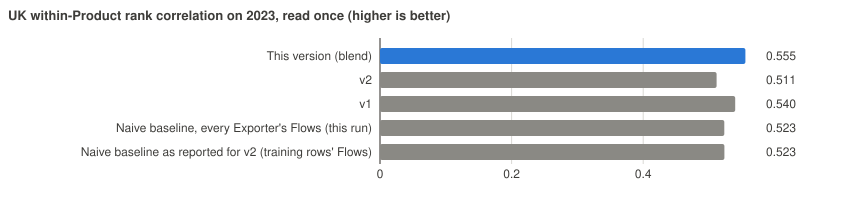

In [5]:
reporting.ranking_by_version(bundle)

**Conclusion.** On 2023, read once, the served model ranks UK Markets more closely to what the UK exported than the Naive Baseline does: the success bar stated in advance is met. v2, the version before it, fell below the Naive Baseline, and v1 sat between the two. The margin is modest, and it is an association on one test year, not a promise of what any Market will buy. Sections 2 to 4 describe the data and the model, section 5 why v2 fell short, section 6 how the model was re-chosen, and section 7 the result and what it cost. Sections 8 to 11 cover Scenarios as Illustrative figures, explanations, the limits and governance, and the conclusions.

## 2. The data: Flows, Zero Cells and policy features

Everything the model knows comes from public trade and country data. This section shows what the target is, how absent trade enters training, and where the policy features come from (*Course:* exploratory data analysis and the data-quality audit, at a scale where the data never sit fully in memory: compact Parquet scanned lazily with Polars).

- **Flows**: CEPII's BACI, HS 2012 revision, release V202601 (ADR 0003). Every non-zero Flow between about 226 Exporters and Importers for about 5,200 Products, 2012â€“2024, about 142 M in all. BACI reconciles each country's export report with its partners' import reports, so a UK Flow is not HMRC's figure. 2024 is provisional: late reporters are still missing.
- **Gravity and size**: distance, contiguity, language and colonial ties from CEPII Gravity; GDP and population from the World Bank, with the IMF and Gravity filling gaps under one written rule that records each value's source.
- **Policy features**: Trade Agreement, Customs Union and EU, CPTPP and EFTA membership per pair and year, from the WTO's RTA database with per-member dates (`docs/research/trade-agreement-coverage.md`), and the Applied Tariff from UNCTAD TRAINS, carried forward from 2021 and zero under an agreement (ADR 0006). These are the only columns a Scenario changes.

Flows per year, with world value and the UK's share of it:

In [6]:
if FIXTURE_MODE:
    flows = build_world().flows.lazy()
else:
    # Downloaded and converted by the BACI build step (`baci.prepare`, in scripts/rebuild.py); read here.
    flows = baci.scan_flows()
flows.head(5).collect()

year,exporter,importer,hs6,value_usd
i16,enum,enum,enum,f64
2012,"""AFG""","""ALB""","""610469""",2734.0
2012,"""AFG""","""ALB""","""630900""",120.0
2012,"""AFG""","""DZA""","""091099""",1185.0
2012,"""AFG""","""ARG""","""392630""",1295.0
2012,"""AFG""","""ARG""","""710310""",98.0


In [7]:
flow_summary = baci.summarise_flows(flows)
flow_summary

year,flows,products,exporters,importers,world_value_usd,uk_value_usd,uk_share
i16,u32,u32,u32,u32,f64,f64,f64
2012,9012155,5199,226,226,1.7973e13,4.3977e11,0.024469
2013,9787220,5199,227,227,1.8226e13,4.4915e11,0.024643
2014,10205742,5199,226,226,1.8463e13,4.7317e11,0.025628
2015,10782381,5199,226,226,1.6230e13,4.1965e11,0.025857
2016,10868820,5199,226,226,1.5814e13,3.9603e11,0.025043
…,…,…,…,…,…,…,…
2020,11150663,5199,226,226,1.7229e13,3.7261e11,0.021627
2021,11673491,5199,226,226,2.1575e13,4.1103e11,0.019051
2022,11677171,5198,226,226,2.4261e13,4.5776e11,0.018868


**Skew.** Flow values are extremely skewed: the mean UK Flow is about a hundred times its median. That is why the model's loss is Tweedie rather than squared error on raw values (*Course:* descriptive statistics: a skewed variable is described by its median, and one huge value can rule a squared loss; section 4).

In [8]:
uk_latest = flows.filter((pl.col("exporter").cast(pl.String) == baci.UK) & (pl.col("value_usd") > 0))
uk_latest.group_by("year").agg(
    mean_usd=pl.col("value_usd").mean(),
    median_usd=pl.col("value_usd").median(),
    markets=pl.col("importer").n_unique(),
    products=pl.col("hs6").n_unique(),
).sort("year").collect()

year,mean_usd,median_usd,markets,products
i16,f64,f64,u32,u32
2012,1.4536e6,24909.0,218,5169
2013,1.3899e6,21228.0,222,5177
2014,1.4260e6,19991.0,222,5166
2015,1.2399e6,17110.0,222,5173
2016,1.1571e6,14837.0,221,5174
…,…,…,…,…
2020,1.0978e6,12682.0,221,5157
2021,1.2207e6,12645.0,222,5158
2022,1.3771e6,12577.0,223,5145


**Zero Cells.** BACI records only non-zero Flows, so an absent pair means zero *or* unreported. A model of Export Potential must also learn where trade does not happen, but the full Exporter Ã— Importer Ã— Product Ã— year grid has about 3.45 bn cells. Training therefore adds **Zero Cells**: the Exporter exports the Product to someone and the Importer imports it from someone, but not from each other. Every UK Zero Cell is kept, because New Market and New Product Opportunities are UK Zero Cells. Other Exporters' are sampled at 5% and weighted by 20, so weighted totals stay unbiased (the Horvitzâ€“Thompson estimator; *Course:* class imbalance, handled by subsampling the majority and reweighting it, so the loss still sees zeros in their true proportion).

Training rows per year, the Zero Cells sampled and the relevant zeros they stand for:

In [9]:
from exportspredictor import features

if FIXTURE_MODE:
    feature_world = build_world()
    feature_table = features.build_features(
        features.training_rows(feature_world.flows, rate=0.5), feature_world.flows, feature_world.sources
    ).lazy()
else:
    feature_dir = features.features_dir()  # written by `python -m exportspredictor.features`; read here, not rebuilt
    feature_table = pl.scan_parquet(feature_dir / "training_*.parquet")

is_zero = pl.col("value_usd") == 0
feature_table.group_by("year").agg(
    rows=pl.len(),
    sampled_zeros=is_zero.sum(),
    relevant_zeros_estimated=pl.col("weight").filter(is_zero).sum(),
).sort("year").collect()

year,rows,sampled_zeros,relevant_zeros_estimated
i16,u32,u32,f64
2012,11558439,3052315,5.1584376e7
2013,12429696,3209063,5.4660132e7
2014,12864385,3284528,5.6076104e7
2015,13551475,3480738,5.9783932e7
2016,13534054,3390731,5.8126653e7
…,…,…,…
2020,13757874,3390789,5.80532e7
2021,14264822,3446737,5.9061523e7
2022,14246975,3449690,5.9009509e7


**Data quality.** Every Exporter and Importer maps to an ISO3 code with Gravity features (the first cell below, real data only). Before trusting BACI as the target, its UK Flows were checked against HMRC's own 2023 Overseas Trade Statistics, an independent primary source (*Course:* the data-quality audit, taken beyond the notes). HMRC records about a sixth more than BACI, almost all for known reasons: value HMRC does not attribute to a Product or Market, and non-monetary gold. Pairs that both sources record agree closely in rank (0.89), so BACI is a sound target for the *shape* of UK trade, which is what the ranking uses (`docs/research/baci-hs12-feasibility.md`).

In [10]:
from exportspredictor import gravity
from exportspredictor.paths import data_dir

if not FIXTURE_MODE:
    # Built by the gravity step (`python -m exportspredictor.gravity`, in scripts/rebuild.py); read here, not rebuilt.
    derived = data_dir() / "derived"
    in_flows = pl.concat(
        [flows.select(baci_iso3=pl.col(side).cast(pl.String)) for side in ["exporter", "importer"]]
    ).unique().collect()
    # Only countries that appear in the 2012-2024 Flows matter; BACI's file also lists retired codes.
    country_map = pl.read_parquet(derived / "country_map.parquet").join(in_flows, on="baci_iso3", how="semi")
    country_year = pl.read_parquet(derived / "country_year.parquet").filter(pl.col("iso3").is_in(country_map["iso3"].implode()))
    print("Exporters and Importers in the Flows:", country_map["baci_iso3"].n_unique())
    print("... with no Gravity pair features:", gravity.unresolved(country_map).height)
    print("... with no WDI data:", country_map.filter(~pl.col("in_wdi")).height)
    display(country_map.filter((pl.col("baci_iso3") != pl.col("iso3")) | pl.col("gravity_proxy").is_not_null()))

Exporters and Importers in the Flows: 227
... with no Gravity pair features: 0
... with no WDI data: 19


baci_code,name,baci_iso3,iso3,gravity_proxy,in_gravity,in_wdi
i64,str,str,str,str,bool,bool
260,"""Fr. South Antarctic Terr.""","""ATF""","""ATF""","""REU""",true,false
490,"""Other Asia, nes""","""S19""","""TWN""",null,true,false
652,"""Saint BarthÃ©lemy""","""BLM""","""BLM""","""GLP""",true,false


In [11]:
if FIXTURE_MODE:
    print("Fixture mode: the HMRC cross-check needs the real downloads (FIXTURE_MODE = False).")
else:
    from exportspredictor import hmrc

    # The allocated OTS table is written by `hmrc.build` (in scripts/rebuild.py); read here, not rebuilt.
    hmrc_check = hmrc.crosscheck(
        hmrc.load(), hmrc.baci_uk_exports(flows, country_map)
    )
    print(hmrc_check["text"])
    display(pl.DataFrame([{key: value for key, value in hmrc_check.items() if key.endswith("_usd")}]))
    display(pl.DataFrame(hmrc_check["by_sector"]))
    display(pl.DataFrame(hmrc_check["by_market"]))
    print(hmrc_check["pairs"])

HMRC's Overseas Trade Statistics record $528.6bn of UK goods exports in 2023 (at $1.2434 per £), 19% more than BACI's $443.0bn. $30.6bn of HMRC's total is not attributed to a Product or a Market, so BACI cannot hold it at HS6 level.


sys:1: UserWarning: POLARS_MAX_BLOCKING_THREAD_COUNT reached (512), this may indicate a deadlock


ots_usd,baci_usd,difference_usd,no_product_usd,no_market_usd,allocated_ots_usd
f64,f64,f64,f64,f64,f64
5.2861e11,4.4295e11,8.5655e10,2.7174e10,3.4067e9,4.9803e11


sector,ots_usd,baci_usd,difference_usd
str,f64,f64,f64
"""71""",8.0818e10,4.4021e10,3.6797e10
"""84""",8.6574e10,7.7297e10,9.2774e9
"""85""",2.8518e10,2.4014e10,4.5040e9
"""29""",1.3579e10,1.0489e10,3.0902e9
"""30""",2.7656e10,2.5081e10,2.5756e9
"""90""",2.1551e10,1.9477e10,2.0739e9
"""28""",1.8405e9,3.5791e9,-1.7386e9
"""22""",1.0813e10,1.2167e10,-1.3544e9
"""89""",1.6053e9,2.7663e9,-1.1610e9


iso3,ots_usd,baci_usd,difference_usd
str,f64,f64,f64
"""CHE""",3.5504e10,7.2625e9,2.8242e10
"""USA""",7.1756e10,6.1056e10,1.0700e10
"""BEL""",2.5238e10,1.7530e10,7.7076e9
"""IRL""",3.4319e10,2.9147e10,5.1724e9
"""IND""",1.2826e10,7.7478e9,5.0785e9
"""NLD""",3.7357e10,3.3201e10,4.1557e9
"""QAT""",4.5298e9,2.3539e9,2.1759e9
"""DEU""",4.0344e10,3.8194e10,2.1493e9
"""ITA""",1.2245e10,1.0140e10,2.1056e9


{'in_both': 219668, 'ots_only': 1739, 'baci_only': 108006, 'spearman': 0.8895008884616545, 'close_share': 0.25, 'close_value_share': 0.5513996983730932}


**Policy features.** A membership counts in a year if it began before 1 July, Gravity's rule: EUâ€“Japan counts from 2019, UKâ€“Australia and UKâ€“New Zealand from 2023, and the UK's CPTPP accession (December 2024) only from 2025. Checked against CEPII Gravity for 2012â€“2021, the two sources agree on every agreement the Scenarios and Event Backtests rely on, and where they differ the reasons are known, mostly gaps in Gravity (*Course:* feature engineering with data lineage: every flag traces to a dated primary record). The UK's Trade Agreements for a few Markets, then the cross-check:

In [12]:
if FIXTURE_MODE:
    print("Fixture mode: the fixture world carries its own trade_agreement column (section 4).")
else:
    policy_files = policy.policy_paths()  # written by `python -m exportspredictor.policy`; read here, not rebuilt
    agreements = pl.read_parquet(policy_files["agreements"])
    trading_blocs = pl.read_parquet(policy_files["trading_blocs"])
    print(agreements.height, "pair-years with a Trade Agreement;", trading_blocs.height, "country-years in a tracked Trading Bloc")

113028 pair-years with a Trade Agreement; 459 country-years in a tracked Trading Bloc


In [13]:
if not FIXTURE_MODE:
    uk_rows = pl.DataFrame(
        {"exporter": "GBR", "importer": ["FRA", "JPN", "AUS", "NZL", "MEX", "USA"]}
    ).join(pl.DataFrame({"year": list(range(2018, 2025))}, schema={"year": pl.Int32}), how="cross")
    uk_policy = policy.attach_policy(uk_rows, agreements, trading_blocs)
    display(uk_policy.pivot(on="year", index="importer", values="trade_agreement"))
    display(uk_policy.pivot(on="year", index="importer", values="customs_union"))
    display(uk_policy.filter(pl.col("importer") == "FRA").select("year", "eu_o", "cptpp_o", "efta_o"))

importer,2018,2019,2020,2021,2022,2023,2024
str,i8,i8,i8,i8,i8,i8,i8
"""FRA""",1,1,1,1,1,1,1
"""JPN""",0,1,1,1,1,1,1
"""AUS""",0,0,0,0,0,1,1
"""NZL""",0,0,0,0,0,1,1
"""MEX""",1,1,1,1,1,1,1
"""USA""",0,0,0,0,0,0,0


importer,2018,2019,2020,2021,2022,2023,2024
str,i8,i8,i8,i8,i8,i8,i8
"""FRA""",1,1,1,0,0,0,0
"""JPN""",0,0,0,0,0,0,0
"""AUS""",0,0,0,0,0,0,0
"""NZL""",0,0,0,0,0,0,0
"""MEX""",0,0,0,0,0,0,0
"""USA""",0,0,0,0,0,0,0


year,eu_o,cptpp_o,efta_o
i32,i8,i8,i8
2018,1,0,0
2019,1,0,0
2020,0,0,0
2021,0,0,0
2022,0,0,0
2023,0,0,0
2024,0,0,0


In [14]:
if not FIXTURE_MODE:
    gravity_policy = policy.read_gravity_policy()  # from the gravity step's extract (section 2)
    crosscheck, disagreements = policy.gravity_crosscheck(agreements, trading_blocs, gravity_policy)
    display(crosscheck)

feature,pair_years,agreement_rate,both,ours_only,gravity_only,positive_overlap
str,u32,f64,u32,u32,u32,f64
"""trade_agreement""",549900,0.955286,58938,21426,3162,0.705625
"""eu""",2350,0.999574,276,0,1,0.99639


**Conclusion.** BACI gives a consistent HS 2012 panel of about 142 M Flows, small enough to scan lazily on one machine, and close to HMRC on the shape of UK trade. Three of its properties shape later choices: values are extremely skewed (a Tweedie loss), absent Flows mean zero or unreported (sampled, reweighted Zero Cells, and weaker rankings where reporting is poor), and 2024 is provisional (a 2023 test year). The policy features come from dated primary records, and they bound what any Scenario Effect can mean.

## 3. Features and the leakage rules

Every model input is computed once, in `exportspredictor.features`, which training and the API both import, so a feature cannot drift between them (*Course:* training/serving skew, removed by construction). This section lists the features, then states the three rules that keep the evaluation honest, each with its reason.

| Group | Features | What it captures |
|---|---|---|
| Gravity | log GDP and population of both countries, log distance, contiguity, common language, colonial tie, common colonizer | size and closeness of the two countries |
| Supply | `log_supply_loo`, `rca_loo`: the Exporter's exports of the Product to *other* Importers, and its revealed comparative advantage | what the Exporter makes and sells well |
| Demand | `log_demand_loo`, `high_income_share_loo`: the Importer's imports of the Product from *other* Exporters, and the share from high-income ones | what the Market buys, and from whom |
| Product | `sector` (HS2 chapter), `relatedness` (closeness to what the Exporter already exports competitively) | Sector differences and nearby capabilities |
| Re-export | `reexport_ratio`: the Importer's exports of the Product against its imports | Re-export Hubs (ADR 0005) |
| Policy | Trade Agreement, Customs Union, EU, CPTPP and EFTA flags; `log_applied_tariff` | the only columns a Scenario changes (ADR 0006) |

### The leakage rules

1. **Out-of-fold scoring** (ADR 0001). UK Productâ€“Market pairs are split into five folds by a hash of the pair, so all of a pair's years share a fold, and each UK Export Potential comes from the fold model that never saw that pair. *Why*: a model that had seen the pair would copy its Actual Exports back and shrink its Export Gap towards zero (*Course:* out-of-fold target encoding, applied to the whole model rather than to one feature).
2. **Leave-one-out supply features.** Every aggregate a row feeds leaves out the row's own Flow, so UK supply of a Product excludes the target Market. *Why*: otherwise the feature contains the answer (*Course:* target leakage: use only what exists without the target). The pair's trade in other Products is left out too, because it would absorb the policy effect. One gap is accepted and recorded in ADR 0001: a non-UK row's demand still includes the UK's Flow to that Market.
3. **The time split.** Fit on 2012â€“2021, choose on 2022, test once on 2023; clip ranges, the Sector encoder and every aggregate are fitted on training years only. *Why*: a choice or a preprocessing step that saw the test year makes its score optimistic, silently (*Course:* preprocessing and evaluation leakage; train, validation and test splits, split by time when predicting later years).

Tests enforce each rule (`tests/test_features.py`, `tests/test_folds.py`): changing a held-out pair's Flow moves none of its own features, and distorting one fold's UK labels a thousandfold leaves that fold's scores unchanged. One UK row's features, whisky (`220830`) to Japan:

In [15]:
feature_table.filter(
    (pl.col("exporter") == "GBR") & (pl.col("importer") == "JPN") & (pl.col("hs6").cast(pl.String) == "220830")
).sort("year").tail(1).collect().transpose(include_header=True, column_names=["value"])

column,value
str,str
"""exporter""","""GBR"""
"""importer""","""JPN"""
"""hs6""","""220830"""
"""year""","""2024"""
"""log_gdp_o""","""28.938148"""
…,…
"""log_applied_tariff""","""0.0"""
"""tariff_imputed""","""true"""
"""mfn_tariff""","""0.0"""


**Conclusion.** One function builds every input for training and serving alike. Three tested rules mean that no UK Export Potential is computed by a model that saw its pair, from a feature that contains its own Flow, or under a choice that saw the test year. The one accepted leak, the UK inside other rows' demand, is small and recorded in ADR 0001.

## 4. The model and how it is scored out-of-fold

The model is one gradient-boosted tree ensemble per fold, trained with XGBoost on the GPU, and the served Export Potential is a **Blend** of it with the Naive Baseline (section 6 says how that form was chosen). This section says what each part does and how a UK pair is scored.

- **Gradient boosting** (*Course:* ensembles: boosting adds small trees that each correct the errors of the last). Depth-12 trees and a learning rate of 0.1, v2's configuration.
- **Tweedie loss** (*Course:* loss functions; choosing a loss for a skewed target). Flows are non-negative, often zero and very skewed. The Tweedie objective models a log mean whose variance grows with the mean, so a few huge Flows do not rule the fit.
- **Monotone constraints** on the policy features: +1 on every membership and âˆ’1 on the Applied Tariff, which is clipped to its training range (ADR 0006). Adding a Trade Agreement never lowers Export Potential; ADR 0008 kept the constraints after testing them against the ranking (section 6).
- **Five fold models** (*Course:* k-fold cross-validation, used here for cross-fitting rather than only for a score). Fold model *k* trains on every non-UK row plus the UK pairs outside fold *k*, and scores only fold *k*.
- **Memory** (*Course:* GPUs and device placement). The 162 M training rows of 2012â€“2023 do not fit the RTX 3080's 10 GB, so they stream year by year into a `QuantileDMatrix`, and the largest hash sample of non-UK rows that fits is kept and reweighted (ADR 0004). Every UK row is kept.

The served configuration, read from the artefact:

In [16]:
{key: bundle.metadata.get(key) for key in ("model_form", "params", "rounds", "n_folds", "non_uk_sampling_rate", "training_seconds")}

{'model_form': {'form': 'blend', 'naive_weight': 0.3},
 'params': {'max_depth': 12,
  'min_child_weight': 3.0468601316016213,
  'subsample': 0.9158324106709628,
  'colsample_bytree': 0.8794644314402613,
  'reg_lambda': 4.953922320798769,
  'tweedie_variance_power': 1.2655329893555092,
  'eta': 0.1},
 'rounds': 1453,
 'n_folds': 5,
 'non_uk_sampling_rate': 0.5894,
 'training_seconds': 4520.29}

### From Export Potential to the Export Gap

The fold models, refit on 2012â€“2023, score the UK grid of each **Gap Period** year, 2022 to 2024, each pair by the fold model that held it out. The **Export Gap** is the mean of the three yearly gaps (Export Potential minus Actual Exports, a year with no Flow counting as $0). Averaging damps the year-to-year noise of single shipments (*Course:* bagging averages to cut variance). 2020 and 2021 are left out because COVID and the end of the Brexit transition describe shocks, not fundamentals. The Baseline table holds the gaps, and the 2024 Export Potential that Scenarios start from:

In [17]:
baseline = bundle.baseline.join(bundle.products, on="hs6", how="left").join(
    bundle.markets.rename({"name": "market"}), on="iso3", how="left"
)
baseline.select(
    pairs=pl.len(),
    products=pl.col("hs6").n_unique(),
    markets=pl.col("iso3").n_unique(),
    pairs_with_exports=(pl.col("actual_exports_usd") > 0).sum(),
    actual_exports_usd=pl.col("actual_exports_usd").sum(),
    export_potential_usd=pl.col("export_potential_usd").sum(),
    baseline_export_potential_usd=pl.col("baseline_export_potential_usd").sum(),
    opportunities=(pl.col("export_gap_usd") > 0).sum(),
)

pairs,products,markets,pairs_with_exports,actual_exports_usd,export_potential_usd,baseline_export_potential_usd,opportunities
u32,u32,u32,u32,f64,f64,f64,u32
1156050,5138,225,416566,3.4618e11,2.7692e11,3.0936e11,1032453


How one pair's Export Gap is formed, year by year: whisky (`220830`) to Japan.

In [18]:
whisky_japan = (pl.col("hs6") == "220830") & (pl.col("iso3") == "JPN")
display(bundle.history.filter(whisky_japan, pl.col("export_gap_usd").is_not_null()))
bundle.baseline.filter(whisky_japan).select(
    "export_potential_usd", "actual_exports_usd", "export_gap_usd", "baseline_export_potential_usd"
)

hs6,iso3,year,actual_exports_usd,export_potential_usd,export_gap_usd,tariff_imputed
str,str,i16,f64,f64,f64,bool
"""220830""","""JPN""",2022,3.06884166e8,3.1452e8,7.6400e6,true
"""220830""","""JPN""",2023,3.14956262e8,2.4812e8,-6.6838e7,true
"""220830""","""JPN""",2024,3.3388241e8,9.0425e7,-2.4346e8,true


export_potential_usd,actual_exports_usd,export_gap_usd,baseline_export_potential_usd
f64,f64,f64,f64
2.1769e8,3.1857e8,-1.0089e8,9.0425e7


**Conclusion.** Every UK Export Potential comes from a fold model that held its pair out, under a loss suited to skewed, zero-heavy Flows and constraints that fix the direction of every policy feature. Every Export Gap averages three recent years. Sections 5 and 6 turn to what the model does well and what the Blend adds.

## 5. What v2 showed

v2, the version before this one, was the model alone, chosen step by step on Tweedie deviance. On 2023 it ranked UK Markets below the Naive Baseline. This section shows two reasons: the measure it was chosen on moved against the ranking, and it was weak on whether the UK exports at all.

### Every choice was made on deviance

Early stopping, the feature ablation, the learning curve and the hyperparameter search (Bayesian, TPE with a median pruner) all chose on the 2022 Tweedie deviance, with the UK ranking only as a guardrail (ADR 0002). The guardrail passed by a hair, âˆ’0.0099 against a limit of âˆ’0.01. Among the three configurations the search confirmed on every Product, the winner had the lowest deviance and the lowest UK ranking (*Course:* loss functions vs evaluation metrics: training optimises the loss it is given, and the metric people read can disagree with it). The search's confirmed configurations, from the artefact (details in the appendix):

In [19]:
pl.DataFrame(bundle.metadata["search"]["confirmation"]).select("trial", "rounds", "validation_deviance", "uk_spearman")

trial,rounds,validation_deviance,uk_spearman
i64,i64,f64,f64
15,1198,364.253023,0.528035
23,1688,365.581411,0.530984
19,1829,365.841244,0.535824


### Weaker on whether the UK exports at all

Most UK pairs are Zero Cells, so a Product's order of Markets is decided largely by which Markets have any UK trade. On the 2022 validation fold, v2's configuration ranks Markets the UK already serves better than the Naive Baseline does (`non_zero_spearman`), but it ranks "any Flow against none" worse (`zero_vs_non_zero_spearman`). Market share knows something about where trade happens that the model lacks. From the experiment loop's record:

In [20]:
record = bundle.metadata["ranking_experiments"]
measures = ["selection_measure", "non_zero_spearman", "zero_vs_non_zero_spearman", "tweedie_deviance"]
pl.DataFrame([
    {"model": f"v2's configuration ({record['noise_floor']['arms'][0]['arm']})", **{m: record["noise_floor"]["arms"][0].get(m) for m in measures}},
    {"model": "Naive Baseline", **{m: record["naive"].get(m) for m in measures}},
])

model,selection_measure,non_zero_spearman,zero_vs_non_zero_spearman,tweedie_deviance
str,f64,f64,f64,f64
"""v2's configuration (seed 0)""",0.533391,0.525292,0.485796,371.6189
"""Naive Baseline""",0.547213,0.449941,0.509227,4331.893122


On 2023, under a comparison with v1 fixed before the test year was read, v2 estimated the size of Flows better than v1 but ranked UK Markets less well. The gain ladder associates most of that drop with v2's new training rows rather than its features or tuning. Both are frozen in the appendix.

**Conclusion.** v2 was a good model of the size of trade: its deviance over all Exporters was the lowest of any version. It was chosen on that, and the ranking an Advisor reads fell below the Naive Baseline. Two lessons carry into section 6: choose on the measure that is reported, and use what the Naive Baseline knows about whether trade happens at all.

## 6. Re-choosing the model on the Selection Measure

The model was re-chosen by an experiment loop (`exportspredictor.loop`, ADR 0008) under a rule fixed in code before any experiment was read. This section explains the rule, then shows every Arm the loop ran, failures included, the five-fold confirmation and the Blend it chose. Everything here is on the 2022 validation year; the loop's data refuse 2023 (`experiments.TestYearRead`). Full detail: `docs/research/opportunity-ranking-experiments.md`.

### The rule

- **Selection Measure**: section 1's headline measure, moved to the validation year: the within-Product rank correlation for held-out UK pairs in 2022, averaged over Products. Every other metric, Tweedie deviance included, is reported and never chosen on. Rounds are early-stopped on it too.
- **Noise Floor**: v2's configuration trained with three seeds, which change both the row sample and XGBoost's seed. The spread of the Selection Measure across seeds is how far it moves by chance (*Course:* seeds, run-to-run noise and the noise band: a gap smaller than the spread between runs is noise, not evidence).
- **Win Threshold**: twice the Noise Floor's standard deviation, and at least 0.005. An Arm is kept only if it beats the best so far by more than this; otherwise every Arm of that experiment is dropped (*Course:* defensible selection and the one-standard-error rule, made stricter and fixed in advance).
- Arms run on one seed against a cached base, so comparisons are paired. No Arm was added or re-run after its result was seen.

In [21]:
summary = model_choice.ranking_summary(bundle.metadata.get("ranking_experiments"))
print(model_choice.how_chosen(bundle.metadata, report)["text"])
None if summary is None else {key: summary[key] for key in ("validation_year", "noise_floor_sd", "win_threshold")}

Every choice was made on one Selection Measure, on 2022 only: Mean over Products of the Spearman correlation between Export Potential and Actual Exports across Markets, on the held-out fold's UK pairs in the validation year, every non-Excluded Product. An Arm was kept only if it beat the best so far by more than the Win Threshold, 0.0089 (twice the Noise Floor's standard deviation, three seeds of one configuration). Of 9 experiments, 1 kept a change (naive baseline).


{'validation_year': 2022,
 'noise_floor_sd': 0.004435207007510482,
 'win_threshold': 0.008870414015020964}

### Every Arm

Seven experiments, in order: blend with the Naive Baseline or start from it; select configurations on ranking (v1's, three from v2's search, shallower trees); a two-part model (whether trade happens, then how much); two Zero Cell scopes; three Product-detail features; and the monotone constraints off. The table lists every Arm with its Selection Measure, its change on the best so far, its best round and whether it was kept; the chart draws each change against the Win Threshold. The first cell also checks that the artefact records the loop's saved results.

In [22]:
ranking_results = bundle.metadata["ranking_experiments"] if FIXTURE_MODE else loop.ranking_record(loop.load())
print("The artefact records the experiment loop's saved results:", ranking_results == bundle.metadata["ranking_experiments"])
with pl.Config(tbl_rows=20):
    display(reporting.experiments(bundle))

The artefact records the experiment loop's saved results: True


experiment,arm,selection_measure,change,rounds,kept,stopped_early
str,str,f64,f64,i64,bool,bool
"""naive baseline""","""blend""",0.577148,0.043757,951,true,false
"""naive baseline""","""starting point""",0.562088,0.028697,13,false,true
"""select on ranking""","""v1""",0.554325,-0.022823,1,false,true
"""select on ranking""","""search trial 15""",0.577148,-1.1102e-16,951,false,false
"""select on ranking""","""search trial 23""",0.579297,0.002149,1697,false,false
"""select on ranking""","""search trial 19""",0.576441,-0.000707,1858,false,false
"""select on ranking""","""depth 6""",0.564495,-0.012653,12,false,true
"""two-part model""","""two-part""",0.562748,-0.0144,400,false,false
"""scope: UK Zero Cells""","""UK Zero Cells sampled""",0.576309,-0.000839,756,false,false


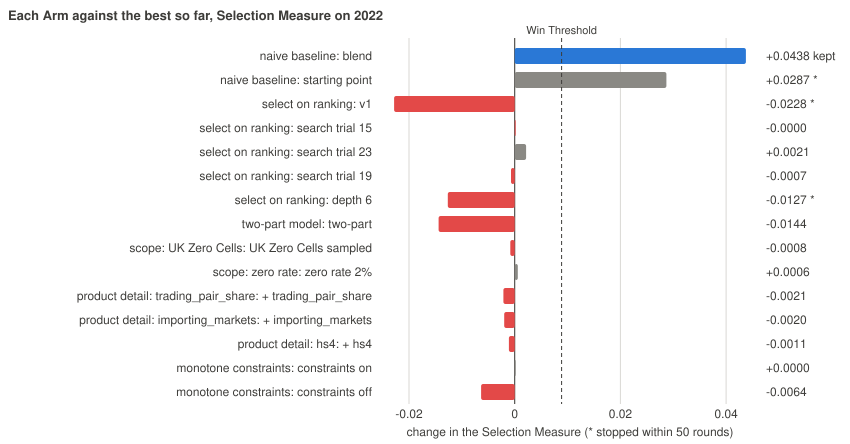

In [23]:
reporting.experiments_chart(bundle)

**The stopping-rule caveat.** Four Arms reached their best round within their first 50 and then stopped: v1's configuration, depth 6, the starting point and the two-part model's binary part (the table shows its size part's rounds). Rounds stop on the model alone, while Arms are chosen on the Blend, so for these four the result reflects the stopping rule as much as the idea; with more patience, or stopping on the Blend, they might have scored higher. The rule was kept, because changing it after seeing results would have meant adding Arms mid-run. A dropped Arm here is not a disproved idea. The one fully trained alternative configuration (search trial 23) still landed inside the noise.

**What the Arms say.** Only the Blend cleared the Win Threshold. Every later Arm landed within about +0.003 of the Blend or below it: the configuration barely matters once blended, the Zero Cell scopes and Product-detail features moved nothing beyond the noise, and removing the monotone constraints ranked slightly worse, so they stay (ADR 0008).

### The five-fold confirmation

A one-fold win could be the luck of the fold. So the Blend and v2 (the same fold model, alone) were trained on all five folds and measured on 2022, each fold model scoring only the UK pairs it held out (*Course:* k-fold cross-validation: a score and its spread across folds). Fold by fold, then over every UK pair of 2022 (`all`):

In [24]:
reporting.confirmation(bundle)

fold,winner,v2,difference,win_threshold
str,f64,f64,f64,f64
"""0""",0.577148,0.533391,0.043757,0.00887
"""1""",0.574481,0.52949,0.044992,0.00887
"""2""",0.575359,0.533813,0.041546,0.00887
"""3""",0.57387,0.528671,0.045198,0.00887
"""4""",0.574761,0.534845,0.039915,0.00887
"""all""",0.563464,0.520579,0.042885,0.00887


The Blend beats v2 on every fold, each time by several times the Win Threshold, and over every pair it also beats the Naive Baseline, which v2 alone does not.

### The Blend

$$\text{Export Potential} = \exp\big(0.7\,\log \text{model} + 0.3\,\log \text{Naive Baseline}\big),$$

each side floored at $1, with the Naive Baseline's weight, 0.3, chosen on the Selection Measure. The two parts know different things. The Naive Baseline orders Markets by whether trade is plausible at all, which is where v2 was weak; the model estimates size among the Markets the UK serves, from gravity, demand, Relatedness and policy. A weighted geometric mean keeps Export Potential in dollars, so the Export Gap is still defined. The Naive Baseline has no policy features, so a Scenario moves only the model's share: every Scenario Effect is the model's, scaled by 0.7 on the log scale (*Course:* ensembles, here two members with a fixed weight chosen as a hyperparameter on validation data).

In [25]:
print(bundle.model_form.text)

Export Potential blends the model (weight 0.7) with the Naive Baseline (weight 0.3) on the log scale.


**Conclusion.** Under a rule fixed before any result was read, seven experiments kept one change: the Blend with the Naive Baseline. It beat v2 on all five folds of 2022, by about five times the Win Threshold overall. Everything else, including four Arms that the stopping rule cut short, stayed inside the noise or below it, and is reported rather than hidden.

## 7. The 2023 result and what it cost

The final run trained the served Blend's fold models and read 2023 once, after the confirmation (*Course:* train, validation and test splits: look at the test set once). This section reads that result beside v2, v1 and the Naive Baseline, then states what choosing on the ranking cost and the one deviation from the rule.

The test-year fold models train on 2012â€“2022 and score 2023, each UK pair by the fold model that held it out, as the Baseline is scored. 2023 shaped no choice: the search, the loop and the confirmation never read it, and a test multiplies every 2023 Flow by 1,000 and checks that the search results do not move.

### The result, read once

Every version's UK ranking and costs, from the evaluation report. Two Naive Baseline rows are shown because their Flows differ slightly (every Exporter's, as the Blend uses, or v2's training rows); they agree closely, so the verdict does not depend on which.

In [26]:
versions = report["earlier_versions"]
pl.from_dicts(versions["rows"] + versions["naive"], infer_schema_length=None)

name,uk_ranking,lift,size_matched_lift,tweedie_deviance_all_exporters,tweedie_deviance_uk,version
str,f64,f64,f64,f64,f64,str
"""This version (blend)""",0.555192,4.993143,0.760532,433.764599,566.346004,null
"""v2""",0.511496,5.226938,0.787659,355.528809,568.588334,"""20261118T100524Z"""
"""v1""",0.53969,null,null,null,null,null
"""Naive baseline, every Exporter…",0.523115,null,null,null,null,null
"""Naive baseline as reported for…",0.523325,null,null,null,null,null


Every metric, model against Naive Baseline, for UK pairs scored out-of-fold and for every Exporter's 2023 rows (*Course:* regression metrics, reported beside the ranking measure rather than chosen on):

In [27]:
pl.DataFrame([{"scope": scope, **result["overall"]} for scope, result in report["accuracy"].items()]).drop("group", strict=False)

scope,rows,non_zero_flows,products,actual_usd,model_tweedie_deviance,naive_tweedie_deviance,model_rmse_log,naive_rmse_log,ranked_products,model_spearman_within_product,naive_spearman_within_product
str,i64,i64,i64,f64,f64,f64,f64,f64,i64,f64,f64
"""all_exporters""",14316140,10851880,5138,1.8688e13,433.764599,3954.686672,2.689804,3.328163,5135,0.734404,0.567774
"""uk_out_of_fold""",1156050,325676,5138,3.5331e11,566.346004,2094.906123,2.348439,2.729484,5138,0.555192,0.523115


### What choosing on the ranking cost

ADR 0008 expected the size of Export Potential to get worse, and it did. The cost, printed from the report:

In [28]:
traded = model_choice.traded_away(report.get("earlier_versions"))
print("No earlier version of this artefact records a lower Tweedie deviance." if traded is None else traded["text"])

Choosing on the ranking traded away accuracy on size: Tweedie deviance over all Exporters is 433.8 for this version against 355.5 for v2 (lower is better), so the size of Export Potential is estimated less well. Size-matched Lift is 0.76 (v2 0.79). Treat dollar values with more caution than rankings.


**Lift.** Lift asks whether large Export Gaps point at growth. The past is replayed on Exporters held out like the UK: gaps over 2015â€“2017, then whether each pair's 2023 Flow rose by at least 50% and $100,000. Raw Lift, the top tenth's growth rate over all pairs', is well above 1, but large gaps sit on large pairs, so the **size-matched Lift** compares the top tenth with pairs of similar Export Potential. It is below 1, as it was for v2 and v1: an Opportunity marks a Market worth a look, not one likelier to grow than its peers of the same size. Lift is a tendency, not a forecast (*Course:* lift as a gate number, here with a cluster bootstrap over Exporters and a size-matched control).

In [29]:
lift = report.get("lift")
print(f"Lift: {NOT_RUN}." if lift is None else lift["text"])
None if lift is None else pl.DataFrame(lift["by_decile"]).rename({"decile": "Export Gap tenth (1 = largest)", "rate": "share that grew", "pairs": "weighted pairs"})

For countries the model never trained on, the tenth of Product–Market pairs with the largest Export Gaps averaged over 2015–2017 rose by at least 50% and $100,000 from their 2015–2017 mean by 2023 5.0 times as often as pairs picked at random (95% confidence interval 3.5 to 8.6): 6% of them against 1%. They grew less often than pairs of similar Export Potential (ratio 0.76, 95% interval 0.68 to 0.83). Much of the Lift comes from size: large gaps sit on large pairs, which grow by $100,000 more easily. This is a tendency across many pairs, not a promise that any one Opportunity will grow.


Export Gap tenth (1 = largest),share that grew,weighted pairs
i64,f64,f64
1,0.05824,859431.0
2,0.007092,859433.0
3,0.002296,859412.0
4,0.001036,859440.0
5,0.000506,859421.0
6,0.000211,859425.0
7,0.000076,859421.0
8,0.000026,859443.0
9,0.000001,859407.0


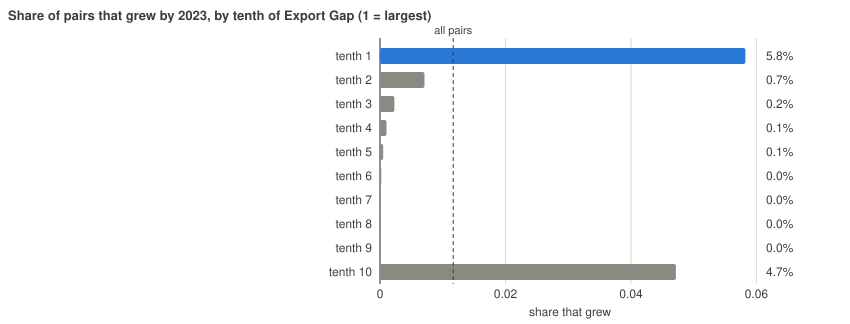

In [30]:
reporting.lift_by_tenth(bundle)

### The one deviation: the served round count

The rule says deviance chooses nothing. The served fold models break it in one place: they trained for v2's round count, which the hyperparameter search early-stopped on Tweedie deviance, scaled to the fold models' rows. The code review found this after 2023 was read. Rebuilding would read 2023 a second time, so the project owner chose not to rebuild. The figures above are those of the served models, and the next rebuild takes its rounds from the Selection Measure (the median of the five-fold confirmation's rounds, then scaled). From the artefact:

In [31]:
reporting.round_count(bundle)

model,chosen_on,rounds_chosen,rounds_trained
str,str,i64,i64
"""served""","""Tweedie deviance (the hyperpar…",1198,1453
"""next rebuild""","""Selection Measure""",1097,null


**Conclusion.** Chosen on the Selection Measure, the Blend beats the Naive Baseline on 2023, the bar set in advance, where v2 did not. The gain cost accuracy on size: Tweedie deviance over all Exporters rose by about a fifth on v2's, and the size-matched Lift stays below 1. So the ranking is the part of the output to trust most, and dollar values deserve more caution. These are associations on one test year, read once, with one disclosed deviation from the rule.

## 8. Scenarios and Blocked Opportunities as Illustrative figures

A **Scenario** asks the served model a what-if question: copy the 2024 Baseline rows of the affected Markets, change **only the policy columns** (Trade Agreement, Customs Union, the Trading Bloc flags and the Applied Tariff that goes with them, ADR 0006), and re-predict each pair through `prediction.export_potential` with the fold model that scored its Baseline (ADR 0001). The **Scenario Effect** is the difference. The Naive Baseline has no policy features, so a Scenario moves only the model's share of the Blend. `exportspredictor.scenarios` checks on every run that no other column moved, so a Scenario cannot report a change in demand as a policy effect.

This section shows the Trading Bloc presets and the Blocked Opportunity values, then sets them beside two benchmarks: a PPML gravity regression and the Event Backtests. That comparison is why every Scenario Effect and Blocked Opportunity value is labelled **Illustrative**: an upper-end association, never a forecast, and never chosen on (ADR 0008). The package's Scenario note, the text the API serves beside every Scenario, comes first (*Course:* the counterfactual test, flip one attribute and hold the rest, used here as a measurement rather than a fairness check; and correlation is not causation: the answer is still learned from correlations in past trade).

In [32]:
from exportspredictor import illustrative, scenarios

note = illustrative.scenario_note(bundle)
print(f"{note['label']}. {note['text']}")
for part in ("benchmark", "model_association", "event_backtest"):
    print("-", note[part]["text"])
if note["blend"] is not None:
    print("-", note["blend"]["text"])

Illustrative. Scenario Effects and Blocked Opportunity values are illustrative: upper-end associations the model has learned from past trade, shown beside their benchmarks. They are not forecasts, and the model was not chosen on them.
- A PPML gravity benchmark (Sector level, 2012–2024) associates a Trade Agreement with +5.1% in Flows (95% interval -0.4% to +11.0%); published estimates range from +21.0% to +100.0%.
- On the served Model Form (Blend), the model associates adding a Trade Agreement with +37.1% in Export Potential over the 678,216 UK pairs without one (weighted by Baseline Export Potential).
- In the primary Event Backtest (The EU–Japan Economic Partnership Agreement), the model alone associated the agreement with +35% for EU exports to Japan; the observed change against Control Markets was +2% (95% interval -7% to +14%). It covers one agreement's Markets and the model alone, while the model's association above covers every UK pair without a Trade Agreement on the served M

### The Trading Bloc presets

Four presets change only the rows of a bloc's member Markets in the Baseline year. **EU re-join** sets the Trade Agreement, Customs Union and EU flags, as for any pair of EU members in training; **EU Customs Union only** sets the Customs Union; **CPTPP** sets the Trade Agreement and CPTPP flags, with accession treated as complete; **Leave** switches off the UK's membership of every bloc it is in. Joining sets a known Applied Tariff to 0 where no agreement existed and leaves a missing one missing; removing an agreement restores the 2021 MFN rate (ADR 0006).

A membership counts in a year only if it began before 1 July, so the 2024 Baseline has no UK CPTPP membership, and the CPTPP preset is a live prediction that 2025 data can check. In 2024 the UK is in no tracked Trading Bloc, so Leave changes nothing. Each preset's Scenario Effect, in dollars and as a share of its Markets' Baseline Export Potential, with its Blocked Opportunities:

In [33]:
preset_results = {
    name: scenarios.run(bundle.baseline_features, bundle.baseline, bundle.fold_models, scenarios.Scenario(preset=name), form=bundle.model_form)
    for name in scenarios.PRESETS
}
pl.DataFrame(
    [
        {
            "preset": scenarios.PRESETS[name].title,
            "pairs_changed": result.pairs.height,
            **result.total(),
            "blocked_opportunities": result.blocked_opportunities().height,
        }
        for name, result in preset_results.items()
    ]
)

preset,pairs_changed,baseline_potential_usd,scenario_potential_usd,effect_usd,effect_share,blocked_opportunities
str,i64,f64,f64,f64,f64,i64
"""EU re-join""",138726,1.3771e11,1.7604e11,3.8323e10,0.278282,5526
"""EU Customs Union only""",138726,1.3771e11,1.6141e11,2.3696e10,0.172072,2369
"""CPTPP""",56518,3.8916e10,4.3614e10,4.6979e9,0.12072,374
"""Leave""",0,0.0,0.0,0.0,0.0,0


On the served artefact, EU re-join adds about $38bn, 28% of its Markets' Baseline Export Potential, and CPTPP about $4.7bn, 12%. The EU figures are large because the model associates intra-EU membership with much denser trade than an agreement alone brings; they describe what the model has learned from EU members' trade, not what re-joining would deliver. CPTPP is smaller because the UK already has agreements with 9 of its 11 members, so for those only the CPTPP flag changes, while Brunei and Malaysia also gain an agreement and a zero tariff and show the largest shares. Per Market:

In [34]:
preset_results["cptpp"].by_market().join(bundle.markets.select("iso3", "name"), on="iso3", how="left")

iso3,baseline_potential_usd,scenario_potential_usd,effect_usd,pairs,effect_share,name
str,f64,f64,f64,u32,f64,str
"""SGP""",6.6080e9,7.6704e9,1.0623e9,5138,0.160764,"""Singapore"""
"""CAN""",8.0487e9,8.9723e9,9.2361e8,5138,0.114753,"""Canada"""
"""AUS""",6.3240e9,7.1682e9,8.4430e8,5138,0.133508,"""Australia"""
"""MYS""",2.5966e9,3.1471e9,5.5050e8,5138,0.212008,"""Malaysia"""
"""JPN""",6.6198e9,7.1634e9,5.4367e8,5138,0.082129,"""Japan"""
…,…,…,…,…,…,…
"""MEX""",3.9590e9,4.2175e9,2.5857e8,5138,0.065311,"""Mexico"""
"""VNM""",1.6253e9,1.7313e9,1.0601e8,5138,0.065223,"""Viet Nam"""
"""CHL""",1.0283e9,1.1076e9,7.9281e7,5138,0.077101,"""Chile"""


### Blocked Opportunity values

For every UK pair with no Trade Agreement in 2024, the **Blocked Opportunity value** is the Scenario Effect of adding one, computed when the artefact is built (`scenarios.blocked_opportunity_values`) through the same prediction function; it is 0 where an agreement already exists. A pair is a **Blocked Opportunity** when that value is at least 20% of its Baseline Export Potential and at least $1M. The app can rank by it, always under the Illustrative label. The largest values are aero-engines, cars and medicines to the USA, China and India: large Markets with which the UK has no agreement. The heading, the total and the CSV export in the app all carry the word "illustrative", so the label travels with the figure when an Advisor copies it into a briefing.

In [35]:
baseline.with_columns(
    blocked_opportunity=scenarios.is_blocked("blocked_opportunity_value_usd", "baseline_export_potential_usd")
).sort("blocked_opportunity_value_usd", descending=True).select(
    "hs6", "description", "market", "export_potential_usd", "blocked_opportunity_value_usd", "blocked_opportunity"
).head(10)

hs6,description,market,export_potential_usd,blocked_opportunity_value_usd,blocked_opportunity
str,str,str,f64,f64,bool
"""841112""","""Turbo-jets: of a thrust exceed…","""USA""",1.2085e9,8.1325e8,true
"""870324""","""Vehicles: spark-ignition inter…","""USA""",1.4673e9,6.3635e8,true
"""841191""","""Turbines: parts of turbo-jets …","""China""",4.4770e8,4.0607e8,true
"""870324""","""Vehicles: spark-ignition inter…","""China""",7.0543e8,3.2686e8,true
"""870323""","""Vehicles: spark-ignition inter…","""USA""",1.3686e9,2.9715e8,true
"""841112""","""Turbo-jets: of a thrust exceed…","""India""",3.0219e8,2.6832e8,true
"""870390""","""Vehicles: for transport of per…","""China""",2.9725e8,2.5433e8,true
"""711319""","""Jewellery: of precious metal (…","""USA""",2.7489e8,2.5175e8,true
"""300490""","""Medicaments: consisting of mix…","""USA""",1.3778e9,2.4648e8,true


### Beside the PPML benchmark

The monotone constraint fixes the *direction* of a Scenario Effect: adding an agreement never lowers Export Potential. Its *size* is only what the trees learned, so it is set beside the method trade economists use: a structural gravity regression fitted by Poisson pseudo-maximum likelihood (PPML, `exportspredictor.ppml`), fitted once and saved with the artefact. Flows are summed to Sector level for 2012, 2015, 2018, 2021 and 2024, three years apart so that trade can adjust:

$$\text{Flow}_{e,i,s,t} = \exp\big(a_{e,s,t} + b_{i,s,t} + c_{e,i,s} + \beta\,\text{TradeAgreement}_{e,i,t}\big)\cdot\varepsilon.$$

The pair effects $c_{e,i,s}$ absorb everything fixed about a pair, including the fact that countries that sign agreements already trade a lot, so $\beta$ is identified only by pairs whose status changed, each compared with itself; $e^{\beta}-1$ is the change the regression associates with an agreement. It is a benchmark only: its pair effects need a pair's own Flows, which a held-out UK pair does not have (ADR 0001), so it could never serve Export Potential (*Course:* linear regression and reading its coefficients, taken further: a log link and Poisson loss so that zeros stay in, fixed effects as a very large one-hot encoding swept out by alternating projections, and standard errors clustered by pair). The model's side is the Blocked Opportunity Scenario recomputed for every UK pair without an agreement through the served Blend. The published estimates are listed with their sources in `docs/research/rta-effects.md`.

In [36]:
reporting.ppml_benchmark(bundle)

estimate,coefficient,effect_pct,low_pct,high_pct,source
str,f64,f64,f64,f64,str
"""PPML benchmark: 3-way fixed ef…",0.050128,5.140596,-0.44273,11.037045,"""fitted once and saved with the…"
"""Model: Trade Agreement Scenari…",0.315572,37.104334,null,null,"""Blocked Opportunity values, 67…"
"""Model: Trade Agreement Scenari…",0.37075,44.882016,null,null,"""same pairs, each weighted equa…"
"""Yotov et al. (2016): PPML, Exp…",0.191,21.045945,null,null,"""Advanced Guide, ch. 1, Table 3…"
"""Head & Mayer (2014): median of…",0.28,32.312981,null,null,"""Handbook of International Econ…"
"""Head & Mayer (2014): mean of 1…",0.36,43.332941,null,null,"""Handbook of International Econ…"
"""Head & Mayer (2014): median of…",0.47,59.999419,null,null,"""Handbook of International Econ…"
"""Yotov et al. (2016): PPML with…",0.557,74.542835,null,null,"""Advanced Guide, ch. 1, Table 3…"
"""Baier & Bergstrand (2007): an …",0.693147,100.0,null,null,"""J. Int. Econ. 71(1), abstract"""


Three readings, all associational.

- **The benchmark is small**: about +5%, with a 95% interval that only just includes zero, below the whole published range (+21% to +100%). The reasons are known: BACI has no intra-national Flows, which more than double the estimate in the WTO/UNCTAD *Advanced Guide*; the agreement dummy is contemporaneous; and many agreements join partners that already trade on low tariffs.
- **The served model's association is about seven times larger**: +37% weighted by Baseline Export Potential over 678,216 UK pairs (+45% as a plain mean per pair). It lies inside the published range but far outside the benchmark's interval on the same Flows and years. v2, the model alone, gave +57%; the Blend's is smaller because only its model share moves.
- **Why the model sits high.** The trees learn the agreement association *across* pairs: pairs with agreements trade more, and the other features cannot absorb everything that makes those pairs close. The benchmark compares each pair with itself; the model cannot, because a held-out UK pair has no pair effect. Part of what the model attributes to an agreement is the closeness of the countries that sign one, the endogeneity Baier and Bergstrand (2007) warn about.

### Beside the Event Backtests

A benchmark is still a model. An **Event Backtest** checks a Scenario Effect against an agreement that really happened (`exportspredictor.backtests`). The primary one is the **EUâ€“Japan Economic Partnership Agreement**, in force from 1 February 2019:

1. Train one model on 2012â€“2018 only. A test multiplies every Flow from 2019 on by 1,000 and checks that the trained model does not change.
2. Predict EUâ€“Japan Flows for 2019â€“2021 with the agreement on and off. The difference is the model's Scenario Effect.
3. Measure what happened with a **difference-in-differences**: the change in EU exports to Japan from 2016â€“2018 to each later year, against the change to ten **Control Markets**, large high-income Markets with no EU agreement in the window, with a 95% interval from resampling Products (*Course:* beyond the notes; it takes the counterfactual test from the model to the observed data).

COVID disrupted 2020 and 2021 unevenly, so 2019 is the cleanest year. A secondary backtest uses the UKâ€“Australia and UKâ€“New Zealand agreements (in force May 2023), scored by the test-year fold models, with provisional 2024 as its only post year. The Event Backtests measure the model alone, trained before the Blend was chosen; a served Scenario Effect is that effect scaled by 0.7 on the log scale.

The EU–Japan Economic Partnership Agreement (in force 1 February 2019), with a model trained only on 2012–2018: For EU exports to Japan in 2019–2021, the model associated the agreement with +35% in Export Potential; the observed difference-in-differences against 10 similar Markets without an agreement was +2% (95% interval -7% to +14%). The model's effect is larger than what was observed, outside the interval. For Japan's exports to the EU in 2019–2021, the model associated the agreement with +42% in Export Potential; the observed difference-in-differences against 10 similar Markets without an agreement was -0% (95% interval -10% to +10%). The model's effect is larger than what was observed, outside the interval.


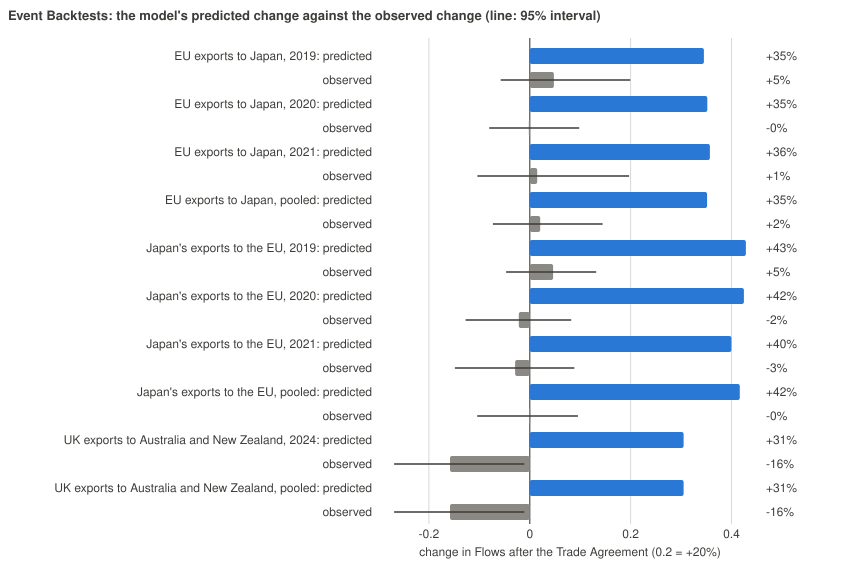

In [37]:
backtest = report.get("event_backtest")
print(f"Event Backtests: {NOT_RUN}." if backtest is None else backtest["text"])
reporting.event_backtests(bundle)

**Conclusion.** Scenarios change only policy columns and re-predict through the served Blend, and the monotone constraint makes every added agreement raise Export Potential. The direction is designed in; the size is not. After the EUâ€“Japan agreement the model alone associated +35% with EU exports to Japan where +2% was observed (95% interval âˆ’7% to +14%), and +42% against about 0% in the other direction; the Blend would serve +23%, still outside the observed interval. For UKâ€“Australia and New Zealand, +31% met an observed fall. The PPML benchmark on the same Flows associates an agreement with +5%, against the served model's +37%. So Scenario Effects and Blocked Opportunity values are **Illustrative**: they show where the model associates an agreement with most trade, and an upper-end order of magnitude, never a forecast of what an agreement will add. The app, the API and the model card show the same Scenario note beside every such figure.

## 9. Explaining Export Potential

An Advisor who takes an Opportunity to a firm must say *why* the model expects more trade. This section shows what drives Export Potential overall and why one pair scores as it does (*Course:* explainability, global against local, and SHAP for local explanations that are additive and faithful to the model you ship).

XGBoost computes exact TreeSHAP values itself, so no background sample is needed. Each pair is explained by **its own fold model**, the one that held it out and scored its Baseline (ADR 0001): any other model would explain a number the Advisor never sees. The Blend is explained as it is served: the model's SHAP values are scaled by its weight, 0.7, and the Naive Baseline's share is attributed half to UK supply and half to Market demand, its two inputs (`prediction.log_contributions`). Contributions add up on the log scale, so the base value plus every contribution reproduces the Export Potential exactly (`tests/test_explain.py`), and on the dollar scale each factor multiplies Export Potential by `exp(contribution)`.

**Global importance** is the mean absolute contribution over a random sample of 2,000 Baseline pairs. Unlike impurity importance, it is measured on the served predictions and cannot credit a feature the model never uses (*Course:* feature importance, impurity against permutation). A sample of 20,000 gave the same top five and moved no feature by more than about 2%, at ten times the run time.

In [38]:
from exportspredictor import explain

importance = explain.global_importance(bundle, sample=2_000)  # about 80 s on the CPU with the depth-12 fold models
importance.with_columns(typical_multiplier=pl.col("mean_abs_contribution").exp())

feature,label,mean_abs_contribution,pairs,typical_multiplier
str,str,f64,i64,f64
"""log_demand_loo""","""How much the Market imports th…",1.343616,2000,3.832879
"""log_supply_loo""","""How much the UK exports this P…",1.099934,2000,3.003967
"""high_income_share_loo""","""Share of the Market's imports …",0.42021,2000,1.522281
"""log_distance""","""Distance from the UK to the Ma…",0.341534,2000,1.407104
"""log_gdp_d""","""Size of the Market's economy (…",0.328088,2000,1.388312
…,…,…,…,…
"""efta_o""","""the UK is a member of EFTA""",0.009836,2000,1.009884
"""common_colonizer""","""the UK and the Market share a …",0.008822,2000,1.008861
"""cptpp_o""","""the UK is a member of CPTPP""",0.008005,2000,1.008037


On the served artefact, demand dominates: how much the Market imports the Product from others moves a typical pair by a factor of about 3.8, and UK supply of the Product to other Markets by about 3.0. Both carry the Naive Baseline's share as well as the model's. Then come the high-income share of the Market's imports (Ã—1.5), distance (Ã—1.4) and the Market's GDP (Ã—1.4). The bloc flags move a typical pair by about 1%: most pairs' policy status never changes, so Scenario Effects rest on a small part of the model, one more reason to read them as Illustrative. Low importance is also a governance signal (*Course:* mean |SHAP| supports data minimisation): the common-colonizer feature adds about 1% and could be dropped at no cost, while the bloc flags stay because Scenarios need them.

**A local explanation.** The largest Opportunity is parts of turbo-jets and turbo-propellers (`841191`) to France. The Why? page shows the same factors in the same words:

In [39]:
top_opportunity = baseline.sort("export_gap_usd", descending=True).row(0, named=True)
why = explain.explain_pair(bundle, top_opportunity["hs6"], top_opportunity["iso3"])
print(f"{top_opportunity['description'][:60]} to {why.market}: Export Potential {explain.usd(why.export_potential_usd)}, scored by fold model {why.fold}")
display(pl.DataFrame([{"factor": f.label, "value": f.value_text, "multiplier": f.multiplier} for f in why.factors[:8]]))
pl.DataFrame([{"year": point.year, "actual_exports_usd": point.actual_exports_usd} for point in why.history])

Turbines: parts of turbo-jets and turbo-propellers to France: Export Potential US$1.4 billion, scored by fold model 2


factor,value,multiplier
str,str,f64
"""How much the UK exports this P…","""US$12.5 billion""",200.082863
"""How much France imports this P…","""US$2.5 billion""",161.912006
"""How specialised the UK is in t…","""8.57× the world average share …",1.724863
"""Distance from the UK to France""","""344 km""",1.673896
"""Size of the UK economy (GDP)""","""US$3.7 trillion""",1.267761
"""How much of this Product Franc…","""Exports 378% of what it import…",1.23956
"""Size of France's economy (GDP)""","""US$3.2 trillion""",1.217055
"""How close this Product is to w…","""37% of its related Products ar…",1.197192


year,actual_exports_usd
i64,f64
2019,8.5219805e7
2020,1.28789098e8
2021,1.02281755e8
2022,1.06717221e8
2023,1.00891032e8
2024,8.3759177e7


The served 2024 Export Potential for UK turbo-jet parts in France is about $1.4bn, from fold model 2, against Actual Exports near $0.1bn in every year since 2019. The factors read as an Advisor would want: the UK exports $12.5bn of this Product to other Markets, France imports $2.5bn of it from others, the UK is 8.6 times as specialised in it as the world average, and France is close. One factor is a warning: France *re-exports* 378% of what it imports of these parts. It hosts large aero-engine and aircraft makers, so much of this trade runs inside supply chains that existing contracts decide. The history adds what the model cannot see: Actual Exports have not moved while Export Potential rose with the provisional 2024 data.

Two limits apply to every explanation. SHAP values are **associations inside the model**: "distance lowers Export Potential" means comparable distant pairs trade less, not that distance causes it. And the largest factors (a Market's size, its imports, distance) are not things an Advisor can change; the actionable reading is the supply side, that the UK already sells this Product well elsewhere (*Course:* actionable explanations).

**Conclusion.** Every Export Potential decomposes exactly into named factors from the fold model that produced it, in words an Advisor can repeat. Globally the served model is driven by what Markets buy and what the UK sells, which is also what the Naive Baseline knows; policy features carry a small part of each prediction. A local explanation read beside the Actual Exports history is the Advisor's main defence against a misleading Opportunity.

## 10. Limits and governance

A result is only as useful as its stated limits. This section reads the known limitations, a sanity check of the top Opportunities and the finding that removed the Uncertain Opportunity badge. It then gives one short entry per governance topic of the course, each pointing to the artefact that is its evidence, and leaves the rest to the model card (*Course:* responsible AI as design constraints with owners and evidence: a commitment without an artefact is an aspiration).

### Known limitations

These are served by the API and shown on the app's Model Evaluation page, so that Advisors can caveat their briefings. Two weigh most: every Applied Tariff after 2021 is carried forward (ADR 0006), and sanctions, prohibitions and other non-tariff barriers are invisible to the model.

In [40]:
with pl.Config(fmt_str_lengths=200, tbl_rows=20):
    display(pl.DataFrame(evaluation.LIMITATIONS))

title,text
str,str
"""Goods only""","""The model covers goods trade only. Services, about half of UK exports, are not in the data."""
"""Tariffs carried forward from 2021""","""Applied Tariffs come from UNCTAD TRAINS, which ends in 2021. 2022–2024, the test year and the whole Gap Period included, reuse each pair's 2021 rate, or 0 where a Trade Agreement entered force after 2…"
"""Excluded Products""","""Crude and refined oil, gas, coal and electricity, bullion and coins, precious-metal scrap, antiques and radioactive elements are Excluded Products: their trade follows pipelines, bullion markets or li…"
"""Trained on the top 100 Exporters""","""The model trains on Flows from the top 100 economies by mean GDP over 2012–2023, the UK always included, into every Market; other Exporters' rows are sampled to fit the GPU. Smaller Exporters still co…"
"""Values are nominal US dollars""","""Every value is in nominal US dollars, as BACI reports it, with no adjustment for inflation or exchange rates. A change between years mixes real trade growth with price and currency movements."""
"""What the Potential Range assumes""","""The Potential Range is calibrated on other Exporters' 2024 Flows, never the UK's, so it assumes UK pairs vary around their Export Potential as comparable pairs of other top-100 Exporters do (exchangea…"
"""Associations, not causes""","""Export Potential and Scenario Effects are associations the model has learned from global trade. ""The model associates a Trade Agreement with +X%"" does not mean the agreement causes +X%, and an Opportu…"
"""Provisional 2024 data""","""The Baseline year, 2024, is provisional in BACI: some countries had not reported when it was built, and it will be revised in the next release. 2024 has about 5% fewer Flows than 2023."""
"""The 2012 product edition""","""Products use HS 2012 codes (BACI's HS12 revision, chosen for its longer history). A few HS6 codes Advisors know from current tariff schedules (HS 2017 or 2022) differ or are split."""


### Sanity check: the top Opportunities

A model can score well and still rank nonsense, so the largest Export Gaps are read as a trade economist would read them. No Excluded Product may appear at all (ADR 0005). Flagged Products and Re-export Hubs stay in the rankings with a caveat, so the share of the top of the list they hold is measured, beside the share of Uncertain Opportunities used below. Then whisky (`220830`), a Product an Advisor knows well.

In [41]:
from exportspredictor.exclusions import is_excluded

top_opportunities = baseline.filter(pl.col("export_gap_usd") > 0).sort("export_gap_usd", descending=True)
display(top_opportunities.select(
    "hs6", "description", "market", "opportunity_type", "export_potential_usd", "actual_exports_usd", "export_gap_usd",
).head(10))
pl.concat(
    [
        top_opportunities.head(top).select(
            top=pl.lit(top),
            excluded_products=is_excluded().sum(),
            flagged_product_share=pl.col("flagged_product").mean(),
            reexport_hub_share=pl.col("reexport_hub").mean(),
            uncertain_share=pl.col("uncertain_opportunity").mean(),
        )
        for top in (20, 100, 1000)
    ]
)

hs6,description,market,opportunity_type,export_potential_usd,actual_exports_usd,export_gap_usd
str,str,str,str,f64,f64,f64
"""841191""","""Turbines: parts of turbo-jets …","""France""","""Expand""",9.2901e8,9.7122e7,8.3189e8
"""841112""","""Turbo-jets: of a thrust exceed…","""China, Hong Kong SAR""","""Expand""",9.6081e8,2.1198e8,7.4882e8
"""841112""","""Turbo-jets: of a thrust exceed…","""China""","""Expand""",9.7269e8,3.2030e8,6.5239e8
"""841112""","""Turbo-jets: of a thrust exceed…","""Türkiye""","""Expand""",5.2829e8,9.0826e7,4.3746e8
"""841112""","""Turbo-jets: of a thrust exceed…","""Germany""","""Expand""",8.9413e8,4.59537415e8,4.3459e8
"""300490""","""Medicaments: consisting of mix…","""France""","""Expand""",7.1824e8,3.9579e8,3.2245e8
"""300490""","""Medicaments: consisting of mix…","""Italy""","""Expand""",3.7907e8,1.0910e8,2.6997e8
"""840820""","""Engines: compression-ignition …","""USA""","""Expand""",3.3881e8,8.0059e7,2.5876e8
"""841191""","""Turbines: parts of turbo-jets …","""China""","""Expand""",4.4770e8,2.1202e8,2.3569e8


top,excluded_products,flagged_product_share,reexport_hub_share,uncertain_share
i32,u32,f64,f64,f64
20,0,0.05,0.05,0.0
100,0,0.04,0.21,0.0
1000,0,0.02,0.19,0.0


In [42]:
baseline.filter(pl.col("hs6") == "220830").sort("export_gap_usd", descending=True).select(
    "market", "export_potential_usd", "actual_exports_usd", "export_gap_usd"
).head(8)

market,export_potential_usd,actual_exports_usd,export_gap_usd
str,f64,f64,f64
"""Netherlands""",2.2446e8,1.32187358e8,9.2270e7
"""Latvia""",7.9836e7,1.2355e7,6.7481e7
"""Malaysia""",9.5846e7,3.9837e7,5.6009e7
"""Russian Federation""",6.4137e7,1.8501e7,4.5635e7
"""China, Hong Kong SAR""",7.6913e7,3.9729156e7,3.7184e7
"""Italy""",1.1546e8,8.4291e7,3.1171e7
"""Ireland""",4.0735e7,1.6492e7,2.4243e7
"""Belgium""",6.8062e7,4.8087e7,1.9974e7


On the served artefact no Excluded Product appears. Flagged Products hold 5% of the top 20 and 2% of the top 1,000. Re-export Hubs hold about a fifth of the top 100 and of the top 1,000 (Hong Kong, Ireland, Belgium, the Netherlands), as expected for large importers of what the UK makes, which is why their rows carry a caveat. The top Opportunities are plausible: aero-engines and their parts (France, Hong Kong, China, TÃ¼rkiye, Germany), packaged medicines (France, Italy, the USA) and engines and aircraft to the USA, all *Expand* pairs in the UK's known strengths. Whisky shows what the model cannot see: the **Russian Federation** ranks fourth, a Market where UK exports collapsed under sanctions from 2022, and no feature records sanctions. An Advisor should read such rows as Barriers the model does not know about, not as Opportunities.

### The Potential Range and the Uncertain Opportunity share

Each UK pair has a **Potential Range**: the range within which Actual Exports fall 80% of the time for pairs of about the same Export Potential (ADR 0007). It is split conformal prediction, calibrated on other Exporters' 2024 rows, never the UK's (a UK residual is its Export Gap with the sign flipped), within 20 bands of Export Potential (Mondrian bands, because Tweedie errors grow with the prediction), with coverage checked on a held-out half of the rows (*Course:* held-out validation, extended from one error figure for the model to a range for each prediction with a coverage guarantee). An Opportunity whose Actual Exports lie inside its range is an **Uncertain Opportunity**: its Export Gap is within the scatter normally seen among comparable pairs. The finding, printed from the evaluation report, then coverage by band:

In [43]:
from exportspredictor import conformal

potential_range = report["potential_range"]
print(conformal.coverage_text(potential_range))
pl.DataFrame(potential_range["by_band"])

On a held-out half of the calibration rows (6,392,004 other Exporters' rows), 85% of their Actual Exports fell inside their Potential Range, against a target of 80%. 904,649 of the 1,032,453 Opportunities (88%) have UK Actual Exports inside their Potential Range (Uncertain Opportunities): most Export Gaps are within the variation normally seen among comparable pairs, so an Export Gap ranks a lead rather than proving one.


band,min_export_potential_usd,rows,coverage
i64,f64,i64,f64
0,0.0,318568,0.898783
1,4.341572,319744,0.894903
2,31.115242,320007,0.881984
3,134.29946,319502,0.860126
4,388.289339,319356,0.833238
…,…,…,…
15,108983.768674,321062,0.802173
16,181900.154707,318451,0.798014
17,327287.259121,319399,0.798891


Coverage on the held-out half is 85% against the 80% target. The excess sits in the smallest bands, where most Actual Exports are exactly $0 and ties widen the range; from an Export Potential of about $1,000 upwards every band is within half a point of 80%. By Exporter, the large, diversified Exporters most like the UK sit near the target, which supports carrying the range over to UK pairs, though that stays an assumption.

**88% of Opportunities are Uncertain Opportunities**, yet none of the top 1,000 by Export Gap is (the sanity check above). Most positive gaps are the small gaps of *New Market* pairs, well inside the ordinary scatter. A badge on nearly nine rows in ten separated nothing, so the badge and its filter were removed from the ranking pages. The share is reported here, on the Model Evaluation page and in the model card, and each pair's range stays on the Why? page (ADR 0007, Outcome). One limit remains: the offsets are dollar amounts within a band, so every pair in the top band gets the same width, about $24M, a sliver for a $1bn pair. A range relative to Export Potential would mean more for large pairs.

### Model card

The course asks for a short card covering intended and out-of-scope use, owner, metrics by group, limitations and data sources, generated from code and versioned with the model, printing UNASSIGNED rather than omitting a section. `governance.model_card` builds it from the artefact, so its numbers are the evaluated ones, and it leads as this notebook does: the headline, the Model Form, the Illustrative Scenario note, how the form was chosen and the Potential Range share, with the frozen results last. The pipeline writes it into each artefact folder; a real run reads it, and the fixture run writes its own. The owner is **UNASSIGNED** on purpose: naming who answers for the model is a decision for the team that adopts it.

In [44]:
from IPython.display import Markdown

from exportspredictor import governance

# The fixture run saves its own artefact and card; the real ones were written by the pipeline and are only read here.
saved_to = artefacts.save(bundle, artefacts_dir()) if FIXTURE_MODE else artefacts_dir() / bundle.version
card_path = governance.write_model_card(bundle, saved_to) if FIXTURE_MODE else saved_to / governance.MODEL_CARD_FILE
Markdown(card_path.read_text(encoding="utf-8"))

# Model card: UK Exports Predictor, version 20261119T001736Z

**Owner:** UNASSIGNED

## Headline

**On 2023, read once, the UK ranking of this version is 0.555: it beats the naive baseline (0.523 from every Exporter's Flows; 0.523 as reported for v2). Earlier versions: v2 0.511, v1 0.540. These are associations on one test year, not a forecast.**

| Version | UK ranking | Size-matched Lift | Lift | Tweedie deviance, all Exporters | Tweedie deviance, UK pairs |
| --- | --- | --- | --- | --- | --- |
| This version (blend) | 0.555 | 0.76 | 4.99 | 433.8 | 566.3 |
| v2 | 0.511 | 0.79 | 5.23 | 355.5 | 568.6 |
| v1 | 0.540 | n/a | n/a | n/a | n/a |
| Naive baseline, every Exporter's Flows (this run) | 0.523 | | | | |
| Naive baseline as reported for v2 (training rows' Flows) | 0.523 | | | | |

Choosing on the ranking traded away accuracy on size: Tweedie deviance over all Exporters is 433.8 for this version against 355.5 for v2 (lower is better), so the size of Export Potential is estimated less well. Size-matched Lift is 0.76 (v2 0.79). Treat dollar values with more caution than rankings.

## Model Form

Export Potential blends the model (weight 0.7) with the Naive Baseline (weight 0.3) on the log scale.

**Model:** XGBoost, Tweedie objective (variance power 1.27), depth 12, 1,453 rounds; 5 out-of-fold models trained on 2012–2023, scoring the 2024 Baseline. Source: BACI V202601.

Disclosed deviation: the served models were trained for 1,453 rounds, the hyperparameter search's 1,198 (early stopping on Tweedie deviance, v2's count) scaled by the ratio of training rows (1.2127). Under ADR 0008 deviance should choose nothing. The artefact was not rebuilt, so that the test year stays read once; the next rebuild uses the median of the five-fold confirmation's rounds (1,097, each chosen by the Selection Measure), scaled the same way.

## Illustrative Scenario Effects

**Illustrative.** Scenario Effects and Blocked Opportunity values are illustrative: upper-end associations the model has learned from past trade, shown beside their benchmarks. They are not forecasts, and the model was not chosen on them.

- A PPML gravity benchmark (Sector level, 2012–2024) associates a Trade Agreement with +5.1% in Flows (95% interval -0.4% to +11.0%); published estimates range from +21.0% to +100.0%.
- On the served Model Form (Blend), the model associates adding a Trade Agreement with +37.1% in Export Potential over the 678,216 UK pairs without one (weighted by Baseline Export Potential).
- In the primary Event Backtest (The EU–Japan Economic Partnership Agreement), the model alone associated the agreement with +35% for EU exports to Japan; the observed change against Control Markets was +2% (95% interval -7% to +14%). It covers one agreement's Markets and the model alone, while the model's association above covers every UK pair without a Trade Agreement on the served Model Form, so the two figures describe different populations and are not compared directly.
- The Event Backtests measured the model alone, before the Blend. The Naive Baseline has no policy features, so a served Scenario Effect is the model's effect scaled by its weight, 0.7, on the log scale, and is smaller. In the primary Event Backtest (The EU–Japan Economic Partnership Agreement), the model's +35% would be served as +23%. Both are associations, not forecasts.

## How the Model Form was chosen

Every choice was made on one Selection Measure, on 2022 only: Mean over Products of the Spearman correlation between Export Potential and Actual Exports across Markets, on the held-out fold's UK pairs in the validation year, every non-Excluded Product. An Arm was kept only if it beat the best so far by more than the Win Threshold, 0.0089 (twice the Noise Floor's standard deviation, three seeds of one configuration).

| Experiment | Best Arm | Selection Measure | Change on the best so far | Kept |
| --- | --- | --- | --- | --- |
| naive baseline | blend | 0.5771 | +0.0438 | blend |
| select on ranking | search trial 23 | 0.5793 | +0.0021 | no |
| two-part model | two-part | 0.5627 | -0.0144 | no |
| scope: UK Zero Cells | UK Zero Cells sampled | 0.5763 | -0.0008 | no |
| scope: zero rate | zero rate 2% | 0.5777 | +0.0006 | no |
| product detail: trading_pair_share | + trading_pair_share | 0.5750 | -0.0021 | no |
| product detail: importing_markets | + importing_markets | 0.5752 | -0.0020 | no |
| product detail: hs4 | + hs4 | 0.5761 | -0.0011 | no |
| monotone constraints | constraints on | 0.5771 | +0.0000 | no |

Confirmed on all 5 folds of 2022: the chosen form 0.5635, v2's form (the model alone) 0.5206, the Naive Baseline 0.5332; difference +0.0429 against a threshold of 0.0089 (confirmed).

## Potential Range

On a held-out half of the calibration rows (6,392,004 other Exporters' rows), 85% of their Actual Exports fell inside their Potential Range, against a target of 80%. 904,649 of the 1,032,453 Opportunities (88%) have UK Actual Exports inside their Potential Range (Uncertain Opportunities): most Export Gaps are within the variation normally seen among comparable pairs, so an Export Gap ranks a lead rather than proving one.

## Metrics

| Metric | Model | Reference (Naive Baseline, chance, or observed) | Note |
| --- | --- | --- | --- |
| UK ranking (headline) | 0.56 | 0.52 | For a typical Product, the model's ranking of Markets for UK exports in 2023, a year it never saw, has a rank correlation of 0.56 with what the UK actually exported (1 would be a perfect ranking, 0 no better than chance). That is only slightly better than the naive baseline (the UK's world market share times each Market's imports), which scores 0.52. |
| Tweedie deviance, all Exporters | 434 | 3,955 | lower is better |
| Tweedie deviance, UK pairs, out-of-fold | 566 | 2,095 | lower is better |
| Lift | 4.99 | 1.00 | 95% interval 3.52 to 8.58 |
| Lift against pairs of similar size | 0.76 | 1.00 | 95% interval 0.68 to 0.83 |
| Event Backtest: EU exports to Japan | +35% | +2% | model's Scenario Effect against the observed change (95% interval -7% to +14%); the model alone, before the blend |
| Event Backtest: Japan's exports to the EU | +42% | -0% | model's Scenario Effect against the observed change (95% interval -10% to +10%); the model alone, before the blend |
| Event Backtest: UK exports to Australia and New Zealand | +31% | -16% | model's Scenario Effect against the observed change (95% interval -27% to -1%); the model alone, before the blend |
| UK ranking, Unclassified Markets | 0.22 | 0.02 | 2,947 UK Flows in 87,346 pairs |
| UK ranking, Low income Markets | 0.27 | 0.24 | 12,804 UK Flows in 128,450 pairs |
| UK ranking, Lower middle income Markets | 0.43 | 0.36 | 48,854 UK Flows in 241,486 pairs |
| UK ranking, Upper middle income Markets | 0.46 | 0.43 | 81,534 UK Flows in 298,004 pairs |
| UK ranking, High income Markets | 0.65 | 0.61 | 179,537 UK Flows in 400,764 pairs |

## Parts not run

- Monotone-constraint comparison: not run for this version. It compares the monotone-constrained model with an unconstrained one. It runs when the pipeline is asked for it (`python -m exportspredictor.pipeline --constraint-comparison`).
- Gain ladder: not run for this version. It splits the change in the v1 comparison's primary metric from v1 to v2 into steps. It runs when the pipeline is asked for it (`python -m exportspredictor.pipeline --gain-ladder`).

## Limitations

- **Only slightly better than a naive ranking for UK pairs.** Within a Product, the model ranks UK Markets with a rank correlation of 0.56, against 0.52 for the UK's market share times each Market's imports. Its value is mostly in the size of Export Potential, not its order.
- **Large Export Gaps mostly mark large pairs.** Lift is 5.0, but against pairs of similar Export Potential it is 0.76: an Opportunity is worth a look, not more likely to grow than its peers of the same size.
- **Scenario Effects are larger than observed changes.** For the EU–Japan Economic Partnership Agreement, the model associated the agreement with +35%, against an observed +2%. Read Scenario Effects as an upper-end association.
- **Trained on a sample of other Exporters' Flows.** The models train on every UK row but a reweighted 58.9% sample of other Exporters' rows (and 5% of their Zero Cells), to fit the GPU's memory. Unbiased, but noisier than training on all rows.
- **Scenario Effects are far above a gravity benchmark.** Over the UK pairs with no Trade Agreement, the model associates adding one (with its tariff removed) with +37.1% Export Potential, Baseline-weighted. A 3-way fixed-effects PPML gravity model on the same Flows associates a Trade Agreement with +5.1% (95% interval −0.4% to +11.0%). Published estimates span about +21% to +100%, but the Event Backtests point the same way as the benchmark: the model overstates the association. Read Scenario Effects as an upper end.
- **The Potential Range is a fixed width in dollars.** Its offsets are fixed amounts of dollars within each band of Export Potential (ADR 0007), so every pair in the top band, from $2.0m of Export Potential upwards, gets the same range, $23.8m wide, whatever its size. For a large pair that range is a sliver, and it is an Uncertain Opportunity only when its Export Gap is under the band's lower offset, $8.2m. Read the badge on large pairs as "a small gap for its size", not as a measure of how sure the model is. A relative (log-scale) range is a candidate for a later version.
- **Goods only.** The model covers goods trade only. Services, about half of UK exports, are not in the data.
- **Tariffs carried forward from 2021.** Applied Tariffs come from UNCTAD TRAINS, which ends in 2021. 2022–2024, the test year and the whole Gap Period included, reuse each pair's 2021 rate, or 0 where a Trade Agreement entered force after 2021 (which overstates liberalisation while its tariff cuts phase in). Tariff changes since 2021 are invisible, and every test-year row is scored on a carried-forward tariff.
- **Excluded Products.** Crude and refined oil, gas, coal and electricity, bullion and coins, precious-metal scrap, antiques and radioactive elements are Excluded Products: their trade follows pipelines, bullion markets or licences the model cannot see. They are never scored or ranked, and every metric here leaves them out.
- **Trained on the top 100 Exporters.** The model trains on Flows from the top 100 economies by mean GDP over 2012–2023, the UK always included, into every Market; other Exporters' rows are sampled to fit the GPU. Smaller Exporters still count in every total the features use, but the model never learns from their own Flows.
- **Values are nominal US dollars.** Every value is in nominal US dollars, as BACI reports it, with no adjustment for inflation or exchange rates. A change between years mixes real trade growth with price and currency movements.
- **What the Potential Range assumes.** The Potential Range is calibrated on other Exporters' 2024 Flows, never the UK's, so it assumes UK pairs vary around their Export Potential as comparable pairs of other top-100 Exporters do (exchangeability). That is assumed, not guaranteed: the coverage check above shows how well it held on held-out rows. It describes how much comparable pairs vary, not a confidence interval for Export Potential, and Scenario Effects get no range.
- **Associations, not causes.** Export Potential and Scenario Effects are associations the model has learned from global trade. "The model associates a Trade Agreement with +X%" does not mean the agreement causes +X%, and an Opportunity is a tendency, not a forecast.
- **Provisional 2024 data.** The Baseline year, 2024, is provisional in BACI: some countries had not reported when it was built, and it will be revised in the next release. 2024 has about 5% fewer Flows than 2023.
- **The 2012 product edition.** Products use HS 2012 codes (BACI's HS12 revision, chosen for its longer history). A few HS6 codes Advisors know from current tariff schedules (HS 2017 or 2022) differ or are split.
- **Reporting quality differs between countries.** BACI reconciles what exporters and importers declare, and countries report with different care and delay. A missing Flow is treated as zero, so the model may be weaker for low-income and poorly reporting Markets; the region breakdown shows where.
- **Sanctions and other non-tariff restrictions are invisible.** Sanctions, embargoes, quotas, licensing and product standards are not model inputs. A Market under sanctions can still show a large Export Gap: Russia ranks high for UK whisky because the model sees its fundamentals, not the sanctions in force since 2022. Check such Markets before acting on them.

## Intended use

- Help government export Advisors decide where to look: rank UK Product–Market pairs by Export Gap (Opportunities) or by the Scenario Effect of adding a Trade Agreement (Blocked Opportunities).
- Explore how the model associates Trade Agreement and Trading Bloc Scenarios with UK Export Potential, as an order of magnitude and a starting point for policy analysis.
- Explain, for one pair, which fundamentals raised or lowered its Export Potential (the Why? page).
- Every output is a lead for a person to check against sector knowledge, not a decision.

## Out-of-scope use

- Forecasting next year's UK exports, or any one pair's future exports: Lift is a tendency across many pairs, not a forecast.
- Quoting a Scenario Effect as what a Trade Agreement would cause: Scenario Effects are associations, and the Event Backtests found them several times larger than the changes observed.
- Decisions about individual firms or people (grants, credit, eligibility). The model holds no data on firms or people, and such uses would change its risk class (EU AI Act, intended purpose).
- Services trade, sanctions, quotas and product standards: none of them is a model input. The Applied Tariff is, but it is carried forward from 2021, so tariff changes after 2021 are invisible to the model.
- Markets under sanctions or embargo: their Export Gaps reflect fundamentals the sanctions override.

## Training scope and sampling

The models train on Flows and Zero Cells of 100 Exporters (the top economies by mean GDP, the UK included) into every Market. Every UK row is kept, with 100% of UK Zero Cells. Other Exporters' Zero Cells are kept at 5%, and their rows are then kept at 58.9%; each sampled row is weighted by the inverse of its rate (Horvitz–Thompson), so weighted totals stay unbiased.

## Features

The model uses 25 features. The 2022 ablation dropped Market import growth: the model without it had both a lower 2022 deviance and a better UK ranking, so it is still built but not trained on.

## Excluded Products

These Products are left out of training, scoring and every ranking and metric (ADR 0005). Country and world totals still count them.

- **Mineral fuels: crude and refined oil, gas, coal and electricity. Their trade follows pipelines, grids and tankers, which the model cannot see.** 36 Products: 270111, 270112, 270119, 270120, 270210, 270220, 270300, 270400, 270500, 270600, 270710, 270720, 270730, 270740, 270750, 270791, 270799, 270810, 270820, 270900, 271000, 271111, 271112, 271113, 271114, 271119, 271121, 271129, 271311, 271312, 271320, 271390, 271410, 271490, 271500, 271600.
- **Radioactive elements: strategic, licensed trade the model cannot see.** 5 Products: 284410, 284420, 284430, 284440, 284450.
- **Silver, gold, platinum-group metals, precious-metal scrap and coins: bullion trade, which is volatile and poorly recorded.** 21 Products: 710610, 710691, 710692, 710811, 710812, 710813, 710820, 711011, 711019, 711021, 711029, 711031, 711039, 711041, 711049, 711230, 711291, 711292, 711299, 711810, 711890.
- **Antiques: one-off objects, not production capacity.** 1 Product: 970600.

## Bias review: Potential Range coverage by Exporter

On a held-out half of the calibration rows, 85% of Actual Exports fell inside their Potential Range (target 80%). Per Exporter, 34 of 99 are within 5 percentage points of the target; the lowest is CHN at 75%.

Too wide (the range overstates their variation), largest excess first: LBY, IRQ, CUB, SDN, COD, BOL, TKM, MAC, ETH, CMR and 55 more.

The UK is never a calibration Exporter (ADR 0007), so its own coverage cannot be measured: the range assumes UK pairs vary as these Exporters' pairs do.

## Data sources

- **BACI HS12 V202601 (CEPII)** (raw/baci): Every non-zero Flow, 2012–2024, reconciled from exporter and importer reports; the model's target and supply and demand features.
- **CEPII Gravity V202211** (raw/gravity): Distance, contiguity, common language, colonial ties; cross-check of agreements to 2021.
- **World Bank WDI and country list** (raw/wdi): GDP and population; regions and income levels.
- **IMF World Economic Outlook** (raw/imf_weo): GDP and population where WDI has none (e.g. Taiwan).
- **WTO Regional Trade Agreements database (RTA-IS)** (raw/wto): Trade Agreements, Customs Unions and Trading Bloc memberships with per-member dates: the policy features.
- **Bank of England, series XUAAUSS** (src/exportspredictor/currency.py): USD → GBP annual average rates, used only to convert HMRC's £ for the cross-check.
- **HMRC Overseas Trade Statistics, 2023 (Open Government Licence v3.0)** (raw/hmrc): Cross-check of BACI's UK totals only; never a model input.
- **UN Statistics Division HS 2022 → HS 2012 conversion table** (raw/hmrc): Puts HMRC's 2023 codes on BACI's revision for the cross-check.
- **UNCTAD TRAINS via the WITS API (reported rates, 2012–2021)** (raw/trains): HS6 MFN and preferential rates: the Applied Tariff, carried forward from 2021 to 2022–2024.
- **UN Statistics Division HS 2017 and HS 2007 → HS 2012 correlation tables** (raw/unsd): Put TRAINS reporter-years on BACI's revision.

## Source versions

- **BACI**: HS12 V202601; downloaded 2026-11-16
- **WTO RTA-IS**: export of all RTAs (unversioned); downloaded 2026-11-16
- **World Bank WDI**: last updated 2026-11-11; downloaded 2026-11-16
- **IMF World Economic Outlook**: DataMapper API (unversioned); downloaded 2026-11-16
- **CEPII Gravity**: V202211; downloaded 2026-11-16
- **Bank of England USD/GBP rate**: series XUAAUSS; downloaded 2026-11-17
- **HMRC Overseas Trade Statistics**: 2023 archive bdsexp_23archive.zip (cross-check only); downloaded 2026-11-17
- **UNCTAD TRAINS**: WITS API, reported rates 2012–2021 (unversioned); downloaded 2026-11-17
- **UNSD HS correlation tables**: HS 2017 and HS 2007 to HS 2012; downloaded 2026-11-17

## Decisions behind the model

- **Train on 100 Exporters into every Market, keeping every UK row (ADR 0004).** The full HS6 world does not fit the GPU's 10 GB. The models train on Flows and Zero Cells of 100 Exporters (the top economies by mean GDP, the UK included) into every Market. Every UK row is kept, with 100% of UK Zero Cells. Other Exporters' Zero Cells are kept at 5%, and their rows are then kept at 58.9%; each sampled row is weighted by the inverse of its rate (Horvitz–Thompson), so weighted totals stay unbiased. The non-UK rate is the largest the VRAM row budget allows, because the learning curve was still falling at the highest rate tried. The budget measured on the RTX 3080 (`scripts/gpu_check.py`) is 100,032,198 rows, about 9% below the about 110 M rows the spec planned around, so the non-UK rate is lower than planned.
- **UK pairs are scored out-of-fold (ADR 0001).** UK Product–Market pairs are split into five folds by a hash of the pair, all years together. Each pair's Export Potential, Scenario Effect and explanation come from the fold model that never saw it, so the Export Gap is not shrunk by memorisation. UK supply features leave the target Market out.
- **One monotone-constrained XGBoost model, blended with the naive baseline (ADR 0002, ADR 0008).** A Tweedie-loss gradient-boosted model serves Opportunities and Scenarios. Every Trade Agreement and Trading Bloc feature has a +1 monotone constraint and the Applied Tariff a −1 constraint, so adding an agreement or cutting a tariff never lowers Export Potential; it does not make the size of the effect right. Since ADR 0008 the form is chosen on the UK ranking alone: the model summary gives the served form and its weights. A blend with the Naive Baseline ranked UK Markets better than the model alone on all five folds of 2022. The Naive Baseline has no policy features, so Scenario Effects come from the model's share only.
- **BACI's HS 2012 revision (ADR 0003).** A longer history (2012–2024) gives the model more agreements that changed during training, and covers the EU–Japan Event Backtest; the cost is 2012-vintage Product codes.
- **Excluded Products, Flagged Products and Re-export Hubs (ADR 0005).** Products whose Flows follow pipelines, bullion markets or licences (Sector 27 except 2712; silver, gold, platinum, precious-metal scrap and coins; antiques; radioactive elements) are dropped from training, scoring, rankings and metrics, though every total still counts them. The rest of Sector 71 is a Flagged Product, and eight entrepôt Markets are Re-export Hubs: both are ranked with a caveat.
- **Applied Tariffs carried forward from 2021 and zeroed under Trade Agreements (ADR 0006).** UNCTAD TRAINS ends in 2021, so 2021 rates are carried forward to 2022–2024 and marked as imputed. A pair whose Trade Agreement entered force after 2021 gets a tariff of 0. Adding an agreement in a Scenario also sets the tariff to 0, and removing one restores the 2021 MFN rate. Tariffs beyond the training range are clipped, so the Scenario Effect of a very large hike flattens.
- **Potential Range calibrated on other Exporters, never the UK (ADR 0007).** An 80% split-conformal range, calibrated within 20 bands of Export Potential on other top-100 Exporters' 2024 rows. UK residuals are the Export Gaps the model exists to find, so calibrating on them would make every gap look normal. An Opportunity whose Actual Exports lie inside its range is an Uncertain Opportunity.
- **Features kept by an ablation on 2022.** Relatedness, Market import growth, the re-export ratio and the Applied Tariff were each removed in turn from a model on a Sector subset and judged on 2022; a feature was dropped when the model without it had both a lower deviance and a better UK ranking. A learning curve over the sampling rates, also on 2022, set the rates.
- **Hyperparameters chosen by a Tree-structured Parzen Estimator search on 2022.** Optuna's TPE with a median pruner replaced v1's five hand-picked configurations, with v1's configuration as trial 0, judged on 2022 Tweedie deviance and guarded by the UK ranking. The fold models reuse the winner, with its round count scaled by the ratio of training rows (a heuristic).
- **The Export Gap is a Gap Period mean (2022–2024).** Each year's Export Potential minus Actual Exports, averaged over three years, steadies the ranking against one-off shipments and leaves out the COVID and Brexit-transition years. Scenarios and Blocked Opportunity values start from the 2024 Baseline.
- **No features from the pair's trade in other Products.** Total bilateral trade would absorb the policy effect, so a Scenario that flips only the policy columns would understate it.
- **Policy features from the WTO RTA-IS.** An agreement counts in a year if in force before 1 July. Partial-scope agreements are excluded. The UK leaves the EU Trading Bloc in 2020 (31 January) but stays in the Customs Union and EU agreements for 2020.
- **Bloc Scenarios change only member Markets' rows.** EU re-join sets the Trade Agreement, Customs Union and EU flags on EU Markets' rows; CPTPP sets the Trade Agreement and CPTPP flags on members' rows; each added agreement zeroes the tariff. A Blocked Opportunity gains at least 20% and $1M.
- **Headline metric: rank correlation within each Product.** Advisors read the model as a ranking of Markets for one Product, so the headline is the within-Product Spearman correlation on the UK's full 2023 grid, out-of-fold, against a naive market-share baseline.
- **Lift and Event Backtests.** Lift ranks held-out Exporters' pairs by their 2015–2017 Export Gap and counts a pair as grown if its 2023 Flow is at least 50% and $100,000 above its 2015–2017 mean, with a size-matched Lift beside it. Event Backtests compare predicted with observed difference-in-differences against the largest high-income Control Markets with no agreement, with the tariff zeroed when the agreement is on.
- **A pre-registered comparison with v1.** v2 is said to beat v1 only if, on the same 2023 UK rows, its within-Product rank correlation is higher with a paired-bootstrap interval above 0, it beats the naive baseline by more than v1 did, and no secondary metric is worse beyond its interval. The rule was fixed before 2023 was read; a gain ladder splits the change.
- **A PPML gravity benchmark for the Trade Agreement Scenario Effect.** A 3-way fixed-effects Poisson pseudo-maximum-likelihood gravity model, at Sector level on the same Flows and scope, gives an independent estimate of what a Trade Agreement is associated with. It is fitted once and saved with the artefact (`python -m exportspredictor.ppml`), beside the model's own association.
- **Values in nominal US dollars.** Every value is in nominal USD, BACI's unit, so figures match international trade sources and need no conversion. The Bank of England's annual averages (XUAAUSS) only convert HMRC's £ for the cross-check.
- **Missing GDP and population stay missing after a stated chain of sources.** WDI, then IMF WEO, then CEPII Gravity, then interpolation; 21 small territories (0.1% of value) stay missing and XGBoost routes them by learned defaults.

## Frozen results

Reported once and no longer extended: they decided v2, not the served Model Form (ADR 0008).

### Comparison with v1

**Verdict.** The result is mixed, so it is reported metric by metric. Not met: no secondary metric gets worse beyond its own interval. On the UK out-of-fold within-Product rank correlation, v2's Export Potential ranks Markets in closer agreement with Actual Exports than v1's (0.555 against 0.540, a difference of +0.016, 95% interval +0.015 to +0.016); against the naive baseline (0.523) the margins are +0.032 for v2 and +0.017 for v1. Tweedie deviance, all Exporters: v1 401.837, v2 433.556 (worse beyond its interval). RMSE of log(1 + value), all Exporters' non-zero Flows: v1 2.844, v2 2.690 (not worse beyond its interval). Size-matched Lift: v1 0.833, v2 0.761 (worse beyond its interval). Raw Lift (shown, not counted): v1 5.798, v2 4.993 (not counted). Event Backtest distance, EU exports to Japan, 2019: v1 0.391, v2 0.298 (not worse beyond its interval). Event Backtest distance, EU exports to Japan, 2020: v1 0.454, v2 0.354 (not counted). Event Backtest distance, EU exports to Japan, 2021: v1 0.444, v2 0.342 (not counted). Event Backtest distance, Japan's exports to the EU, 2019: v1 0.295, v2 0.383 (not worse beyond its interval). Event Backtest distance, Japan's exports to the EU, 2020: v1 0.361, v2 0.447 (not counted). Event Backtest distance, Japan's exports to the EU, 2021: v1 0.371, v2 0.429 (not counted).

Primary metric (UK out-of-fold within-Product rank correlation): v1 0.540, v2 0.555, naive 0.523; v2 − v1 +0.016 (95% interval +0.015 to +0.016).


### Data lineage

Every served number should trace back to exact inputs (*Course:* data lineage and reproducible artefacts). Raw downloads are fingerprinted with their size and SHA-256 (`governance.data_lineage`), including the 1,294 UNCTAD TRAINS files and the UN HS concordances. Every derived table is rebuilt by one command, in the order of `scripts/rebuild.py`. Each artefact is a folder named by its UTC timestamp, whose metadata records the BACI release, the Exporter scope, the sampling rates and seed, the parameters, the XGBoost version and the device, and `copied_from` for a version derived from another (*Course:* registry versions). The API serves the newest complete folder, so rolling back means removing it. One gap remains: the artefact does not yet store the raw-file hashes, so proving which download a version was trained on relies on the data folder not having changed.

In [45]:
if FIXTURE_MODE:
    print("Fixture mode: the fixture world is generated in code (exportspredictor.fixture), so there are no raw files to fingerprint.")
else:
    lineage = governance.data_lineage()  # hashes about 2.8 GB of downloads, under a minute
    display(lineage.group_by("source").agg(files=pl.len(), bytes=pl.col("bytes").sum()).sort("source"))
    display(lineage.filter(pl.col("source").is_in(["UNCTAD TRAINS", "UN HS concordances"])))
{
    **{key: bundle.metadata.get(key) for key in (
        "version", "source", "xgboost_version", "device", "zero_sampling_rate", "uk_zero_sampling_rate",
        "zero_sampling_seed", "non_uk_sampling_rate", "created_at", "copied_from",
    )},
    "exporters_in_scope": len(bundle.metadata.get("exporter_scope") or []),
}

source,files,bytes
str,u32,i64
"""BACI HS12 V202601 (CEPII)""",4,1268530150
"""CEPII Gravity V202211""",5,1458141032
"""HMRC OTS 2023 and UN HS concor…",2,36393610
"""IMF World Economic Outlook""",2,308389
"""UN HS concordances""",2,896843
"""UNCTAD TRAINS""",1294,61413650
"""WTO RTA-IS""",1,207439
"""World Bank WDI""",3,1541836
"""World Bank country list""",1,113954


source,file,bytes,sha256
str,str,i64,str
"""UNCTAD TRAINS""","""raw/trains/2012/ABW.parquet""",14767,"""fc94b324f3cba023b117ac9669546a…"
"""UNCTAD TRAINS""","""raw/trains/2012/AFG.parquet""",16294,"""b3e2e95e9c065d4c406ca84a30d217…"
"""UNCTAD TRAINS""","""raw/trains/2012/AGO.parquet""",15028,"""97f0edbc48b2ae43b69c91d46c9fc0…"
"""UNCTAD TRAINS""","""raw/trains/2012/AIA.parquet""",14790,"""7daaafd69c3e0871a62178a4504bf7…"
"""UNCTAD TRAINS""","""raw/trains/2012/ALB.parquet""",43916,"""6a7b9357f431937a878ddac8b04e4f…"
…,…,…,…
"""UNCTAD TRAINS""","""raw/trains/availability.xml""",2125532,"""271d5ed9ba9a7d9111877011ca79a4…"
"""UNCTAD TRAINS""","""raw/trains/countries.xml""",116491,"""6ce9747d24d4c53897d8f455a664d8…"
"""UNCTAD TRAINS""","""raw/trains/manifest.json""",250,"""653f208bf8d9ba797b29002c141419…"


{'version': '20261119T001736Z',
 'source': 'BACI V202601',
 'xgboost_version': '3.4.1',
 'device': 'cuda',
 'zero_sampling_rate': 0.05,
 'uk_zero_sampling_rate': 1.0,
 'zero_sampling_seed': 0,
 'non_uk_sampling_rate': 0.5894,
 'created_at': '2026-11-18T18:59:10.355703+00:00',
 'copied_from': None,
 'exporters_in_scope': 100}

### Bias review

Bias here concerns countries and Sectors, not people: the model holds no personal data. BACI is built from what countries report, and poorer countries report later and less completely, so absent Flows read as zeros make a poorly reporting Market look as if it buys little (data bias). One loss, dominated by large Flows, serves every Market (objective bias). The review is a representation audit and a worst-group evaluation on the UK's 2023 out-of-fold grid, by region and by World Bank income level as a stand-in for reporting quality; a group with fewer than 500 UK Flows is flagged thin (*Course:* representation audit, and evaluating beyond the average).

In [46]:
uk_accuracy = report["accuracy"]["uk_out_of_fold"]
bias_columns = ["group", "rows", "non_zero_flows", "actual_usd", "model_spearman_within_product", "naive_spearman_within_product"]
for breakdown in ("by_region", "by_income"):
    if uk_accuracy.get(breakdown):
        display(pl.DataFrame(uk_accuracy[breakdown]).select(bias_columns).with_columns(thin=pl.col("non_zero_flows") < 500))
pl.DataFrame(uk_accuracy["by_sector"]).select(bias_columns).head(5)  # the weakest Sectors (HS chapters)

group,rows,non_zero_flows,actual_usd,model_spearman_within_product,naive_spearman_within_product,thin
str,i64,i64,f64,f64,f64,bool
"""Unclassified""",87346,2947,1.47759136e8,0.221549,0.02199,false
"""Latin America & Caribbean""",200382,40883,9.6724e9,0.34944,0.306922,false
"""Sub-Saharan Africa""",246624,48109,6.3658e9,0.38647,0.356822,false
"""Middle East, North Africa, Afg…",118174,39716,2.5255e10,0.496008,0.420434,false
"""East Asia & Pacific""",195244,48692,6.0684e10,0.626604,0.613288,false
"""South Asia""",30828,8654,6.7134e9,0.645978,0.551349,false
"""Europe & Central Asia""",262038,126883,1.8306e11,0.65174,0.559288,false
"""North America""",15414,9792,6.1406e10,0.82457,0.802258,false


group,rows,non_zero_flows,actual_usd,model_spearman_within_product,naive_spearman_within_product,thin
str,i64,i64,f64,f64,f64,bool
"""Unclassified""",87346,2947,1.47759136e8,0.221549,0.02199,false
"""Low income""",128450,12804,1.0545e9,0.272753,0.237496,false
"""Lower middle income""",241486,48854,1.4618e10,0.427584,0.360384,false
"""Upper middle income""",298004,81534,4.4697e10,0.461012,0.431174,false
"""High income""",400764,179537,2.9279e11,0.651353,0.605854,false


group,rows,non_zero_flows,actual_usd,model_spearman_within_product,naive_spearman_within_product
str,i64,i64,f64,f64,f64
"""26""",8325,409,1.98877305e8,0.242883,0.30018
"""03""",42525,2280,2.4798e9,0.254767,0.271737
"""01""",7650,459,8.32025155e8,0.272072,0.279031
"""47""",4725,350,6.28650212e8,0.281897,0.320482
"""23""",5175,583,1.5002e9,0.319494,0.31737


The gradient is steep: the Blend ranks UK Markets at 0.65 in high-income Markets and 0.27 in low-income ones, and by region from 0.82 (North America) to 0.35 (Latin America and the Caribbean). It is mostly a data effect: in low-income Markets only about one UK pair in ten has any trade, so the rankings are among near-zero Flows that BACI measures least well. The Blend beats the Naive Baseline in every group, and no group is thin. By Sector the weakest are commodities, such as ores, fish, live animals and wood pulp, where sanitary rules, quotas and logistics decide Markets and the model sees none of them; there the Naive Baseline often ranks better. The cost falls on developing Markets: an Advisor reading the rankings at face value would see fewer, noisier Opportunities there, for reasons of data quality rather than fundamentals. The mitigations in place are the region breakdown on the Model Evaluation page and a region filter on every ranking; per-group thresholds (*Course:* per-group thresholds) would come next if the rankings were used to allocate budgets.

### Regulation

**EU AI Act.** Intended purpose decides the tier, not the technique (*Course:* the EU AI Act's risk tiers). The purpose here is decision support for public export promotion, from aggregate trade statistics about countries and Products, never natural persons. The system is not prohibited and not high-risk (no Annex III use, not a safety component), and it neither talks to people as if human nor generates synthetic content, so it is **minimal risk**, with no new legal duties. A UK government tool used in the UK falls outside the Act anyway, but classifying it is the right discipline. **Function creep would change the tier**: scoring individual firms for grants would be a decision about specific businesses, so the model card lists it as out of scope.

**The UK approach** has no AI statute: regulators apply five principles, and the course asks for an artefact per principle. Safety and robustness: the time split, the leakage tests and the Event Backtests. Transparency: the Why? page and the model card. Fairness: the bias review. Accountability: versioned artefacts, ADRs and the decision log, with the owner still UNASSIGNED. Contestability: outputs are leads that Advisors decide on, each with its explanation. The data are country-level aggregates, so UK GDPR is not engaged.

### Drift

A trained model is frozen while trade moves (*Course:* model drift, its three types, and the Population Stability Index). **Data drift** is checked with each feature's PSI on the UK grid, 2023 against 2024: stable below 0.10, act above 0.20. **Concept drift**, the same fundamentals bringing different trade after new tariffs or sanctions, shows only as falling accuracy, so it needs the yearly re-evaluation. **Label drift** comes from BACI revising its provisional year. Then the stability of the rankings between the two years, scored by the same models:

In [47]:
if FIXTURE_MODE:
    last_year = feature_table.select(pl.col("year").max()).collect().item()
    drift_reference = feature_table.filter(pl.col("year") == last_year - 1).collect()
    drift_current = feature_table.filter(pl.col("year") == last_year).collect()
else:
    drift_reference = pl.read_parquet(feature_dir / "uk_grid_2023.parquet")
    drift_current = pl.read_parquet(feature_dir / "uk_grid_2024.parquet")
display(governance.feature_drift(drift_reference, drift_current, features.FEATURES))
print(report["stability"]["text"])

feature,psi,status
str,f64,str
"""log_gdp_o""",10.543652,"""act"""
"""log_population_o""",10.543652,"""act"""
"""relatedness""",0.243515,"""act"""
"""high_income_share_loo""",0.007534,"""stable"""
"""log_gdp_d""",0.00541,"""stable"""
…,…,…
"""eu_d""",0.0,"""stable"""
"""cptpp_o""",0.0,"""stable"""
"""efta_o""",0.0,"""stable"""


Scored by the same models, each Product's ranking of Markets by Export Potential in 2024 has a rank correlation of 0.86 with its 2023 ranking, and 62% of the top 1,000 Opportunities by Export Gap are the same in both years.


Every Market-side feature is stable. Three read *act*, for known reasons: the UK's own GDP and population take one value per year on the UK grid, so any change moves every row (PSI is the wrong test for a constant, which the clip ranges fitted on training years guard instead), and Relatedness, a UK-side feature, moves with the provisional 2024 export basket and is the one to watch. The Applied Tariff cannot drift because it is carried forward, which is a limit of the data, not evidence of stability. Rankings are broadly stable between 2023 and 2024, but only about three in five of the top 1,000 Opportunities are the same, another reason the Export Gap averages the Gap Period.

**The yearly refresh** follows each January's BACI release: rebuild, check the inputs (the HMRC cross-check and PSI), retrain with the test year moved on, promote only if the Naive Baseline is beaten, and use the 2025 data as the first live test of the CPTPP Scenario.

**Conclusion.** The limits are measured and stated where the numbers are read. The top Opportunities are plausible, but sanctions and prohibitions are invisible to the model. 88% of Opportunities lie inside their Potential Range, so that share is reported as a finding instead of a badge that marked almost every row. The model ranks UK Markets much better where trade data are good, and Advisors are told so. Governance has an artefact for each course topic: a generated model card, fingerprinted inputs and versioned artefacts, a bias review, a minimal-risk classification with function creep ruled out of scope, and drift checks with a yearly refresh. The open gaps are named: no owner, raw-file hashes not stored in the artefact, and no per-region thresholds.

## 11. Conclusions

The question was whether a model trained on global trade can tell Advisors where to look first better than a market-share rule. This section says what worked, what did not, and what the project would do next.

**What worked**

- **The ranking beats the Naive Baseline on 2023**, read once: 0.555 against 0.523, where v2 (0.511) did not and v1 (0.540) did by less. The bar was set before the test year was read.
- **Choosing on the measure that is reported.** The Selection Measure, a Noise Floor from three seeds and a Win Threshold fixed in code turned seven experiments into one kept change, the Blend, confirmed on all five folds of 2022 (*Course:* defensible selection, made stricter and fixed in advance).
- **The integrity rules held.** Out-of-fold scoring, leave-one-out features and the time split are tested, so no reported UK figure comes from a model that saw its pair or a choice that saw the test year.
- **Honest labels.** Scenario Effects are shown as Illustrative beside a PPML benchmark and the Event Backtests, and the Uncertain Opportunity share replaced a badge that separated nothing.
- **Methods beyond the notes**: out-of-fold cross-fitting, Tweedie loss with Horvitzâ€“Thompson weighted Zero Cells, monotone constraints, split conformal prediction with Mondrian bands, PPML with three-way fixed effects, difference-in-differences backtests, a pre-registered comparison with a paired bootstrap, and a size-matched Lift with a cluster bootstrap.

**What an Advisor gets.** For any Product, the Markets ranked by UK Export Potential, with the Export Gap that says where comparable Exporters sell more than the UK does. Each Opportunity comes with its explanation on the Why? page, its Actual Exports history and its Potential Range, so a lead can be checked before it is taken to a firm. The Scenarios and Blocked Opportunities pages answer "what does the model associate with an agreement here?", always beside the PPML benchmark and the Event Backtest result. The Model Evaluation page states the 2023 result, the cost in size, the Lift and the limitations in the words this notebook uses. What the Advisor does not get is a forecast: every figure is an association learned from global trade, and the ranking is the part to trust most.

**What did not**

- **v2's tuning.** Every v2 choice was made on Tweedie deviance, and the ranking Advisors read fell below the Naive Baseline (section 5). The search, the ablation and the learning curve are now frozen results.
- **Size got worse.** Chosen on the ranking, the Blend's deviance over all Exporters rose by about a fifth on v2's, and its size-matched Lift stays below 1 (0.76): an Opportunity marks a Market worth a look, not one likelier to grow than its peers of the same size.
- **Scenario Effects are too large**: +35% predicted against +2% observed after EUâ€“Japan, and +37% against a +5% benchmark. The monotone constraint makes the direction consistent; it does not make the size right.
- **Four Arms were cut short** by a stopping rule on the model alone, so their ideas are untested rather than disproved.
- **One deviation from the rule**: the served round count came from v2's deviance search, and the next rebuild takes it from the Selection Measure.

**What next**, in order of value:

1. **Rebuild on the Selection Measure's round count**, then let the next BACI release's test year decide, under the same rule.
2. **Re-run the Arms the stopping rule cut short** (v1's configuration, shallower trees, the two-part model), with more patience or stopping on the Blend, as new pre-registered experiments.
3. **Calibrate Scenario Effects** against the PPML benchmark and a pool of Event Backtests, and report a range rather than a point.
4. **Make the Potential Range relative to Export Potential**, so that it means something for large pairs.
5. **Add sanctions and post-2021 tariffs** when a source allows, so that Russia-style Opportunities disappear and tariff Scenarios start from current rates.
6. **Try an entity-embedding network** for Exporters, Importers and Products under the same rule; the course's advice that trees win on tabular data is the hypothesis to beat (*Course:* embeddings).
7. **Name an owner**, store the lineage hashes in the artefact, and use the 2025 data as the first live test of the CPTPP Scenario.

**Conclusion.** The UK Exports Predictor is a tool for deciding *where to look*. Chosen on the measure Advisors read, it ranks UK Markets better than a market-share rule on a year it never saw, by a modest margin, and its weaknesses are measured rather than hidden: dollar values deserve less trust than rankings, and Scenario Effects are illustrative upper ends. Its numbers are associations learned from global trade, useful for prioritising conversations with industry and never a promise of what a Market or an agreement will deliver.

## Appendix: frozen results

These parts chose or checked v2 and no longer decide anything (ADR 0008). Each is one short reported result, read from the artefact or the saved experiment results, with a link to its detail. None is extended, re-run or re-tuned here, and a part this artefact version did not run says so. Each entry names the course concept it applied. They are kept because they explain how v2 came to be and why it fell short, and because the code that produced them still runs and is still tested; deleting them would hide the path that led to the Selection Measure.

### The hyperparameter search

v2's search (Optuna's TPE sampler with a median pruner; *Course:* grid and random search, taken to Bayesian optimisation) ran 27 trials on a Sector subset and retrained the best three on every Product, choosing on 2022 Tweedie deviance with the UK ranking as a guardrail. Trial 15 won: depth 12, variance power 1.27, 1,198 rounds, with the lowest deviance (364.3) and the lowest UK ranking of the three (0.528 against 0.531 and 0.536). The guardrail passed by a hair, âˆ’0.0099 against âˆ’0.01. Its rounds, scaled to 1,453, are the served round count (section 7). Detail: ADR 0002 and ADR 0008.

In [48]:
from exportspredictor import search

search_results = bundle.metadata["search"]
winner = search_results["winner"]
print(
    f"Winner: trial {winner['trial']}, {winner['rounds']} rounds; UK ranking against v1's configuration "
    f"{search_results['spearman_vs_v1']} (guardrail {search.SPEARMAN_GUARDRAIL})"
)
{name: winner["params"][name] for name in search.SPACE}

Winner: trial 15, 1198 rounds; UK ranking against v1's configuration -0.009862442991146247 (guardrail 0.01)


{'max_depth': 12,
 'min_child_weight': 3.0468601316016213,
 'subsample': 0.9158324106709628,
 'colsample_bytree': 0.8794644314402613,
 'reg_lambda': 4.953922320798769,
 'tweedie_variance_power': 1.2655329893555092}

### The feature ablation

One model with every feature, then one without each of v2's four candidate features, on one fold and a Sector subset, measured on 2022 (*Course:* drop-column importance, the retrain-without-it cousin of permutation importance; a feature with no signal adds variance and removes no bias). A feature was dropped only if the model without it was better on both deviance and the UK ranking. Market import growth was dropped; Relatedness and the re-export ratio were kept on deviance, and the Applied Tariff by rule, because tariff Scenarios need it. Every model without one feature ranked UK pairs slightly better, which looks more like one-fold noise than signal. Detail: `exportspredictor.experiments`.

In [49]:
ablation = pl.DataFrame(experiment_results["ablation"])
print("Dropped:", [f for f in features.ALL_FEATURES if f not in experiment_results["kept_features"]] or "none")
ablation.select(
    "dropped", "features", "training_rows", "rounds", "validation_deviance", "deviance_change",
    "uk_spearman", "spearman_change", "hurts",
)

Dropped: ['market_import_growth']


dropped,features,training_rows,rounds,validation_deviance,deviance_change,uk_spearman,spearman_change,hurts
str,i64,i64,i64,f64,f64,f64,f64,bool
null,26,17672976,1500,416.174803,0.0,0.600058,0.0,false
"""relatedness""",25,17672976,1499,426.398637,10.223834,0.609327,0.009269,false
"""market_import_growth""",25,17672976,1500,412.031334,-4.143469,0.611922,0.011864,true
"""reexport_ratio""",25,17672976,1500,418.65466,2.479857,0.613904,0.013846,false
"""log_applied_tariff""",25,17672976,1500,416.372992,0.198189,0.604804,0.004746,false


### The learning curve

The same model at non-UK sampling rates of 0.1, 0.3 and 0.65 and Zero Cell rates of 2%, 5% and 10% (*Course:* the biasâ€“variance trade-off, read along the data axis rather than model complexity). Deviance was still falling at the highest rate, by 4â€“6% from 0.3 to 0.65, so the model is variance-limited on large Flows and trains on every non-UK row the VRAM budget allows; the Zero Cell rate stayed at 5%. The UK ranking moved by less than 0.01 across the grid: more rows sharpen the scale of Export Potential more than its order. Detail: ADR 0004.

In [50]:
curve = pl.DataFrame(experiment_results["learning_curve"])
curve.select(
    "zero_rate", "non_uk_rate", "training_rows", "rounds", "validation_deviance", "uk_spearman",
    "full_data_non_uk_rate", "fits_budget",
)

zero_rate,non_uk_rate,training_rows,rounds,validation_deviance,uk_spearman,full_data_non_uk_rate,fits_budget
f64,f64,i64,i64,f64,f64,f64,bool
0.02,0.1,3382964,1485,495.781062,0.615492,0.8442,true
0.02,0.3,7888215,1500,441.054588,0.6141,0.8442,true
0.02,0.65,15771926,1500,413.551139,0.60924,0.8442,true
0.05,0.1,3675931,1479,495.897508,0.613986,0.7292,true
0.05,0.3,8766112,1500,438.636137,0.608061,0.7292,true
0.05,0.65,17672976,1500,412.068375,0.606893,0.7292,true
0.1,0.1,4163009,815,456.019266,0.597747,0.5943,true
0.1,0.3,10229822,1401,429.605121,0.600998,0.5943,true
0.1,0.65,20838721,1500,413.842076,0.599603,0.5943,false


### The v1 comparison

Before 2023 was read, a rule was fixed for whether a new version beats v1 (*Course:* touch the test set once, applied to the comparison itself): the primary metric's paired-bootstrap interval lies above 0, the margin over the Naive Baseline is larger than v1's, and no secondary metric is worse beyond its interval. v1 is never re-run; its frozen tables are checksummed. Under that rule v2 did not beat v1 (0.511 against 0.540). Run for the served Blend with the same code, which calls the newer version "v2", the result is **mixed**: the Blend ranks better than v1 (0.555 against 0.540, interval above 0) and beats the Naive Baseline by more, but its Tweedie deviance and size-matched Lift are worse beyond their intervals, the cost section 7 reports. Detail: `exportspredictor.comparison`.

In [51]:
v1_comparison = report.get("v1_comparison")
print(f"The v1 comparison: {NOT_RUN}." if v1_comparison is None else v1_comparison["verdict"]["text"])

The result is mixed, so it is reported metric by metric. Not met: no secondary metric gets worse beyond its own interval. On the UK out-of-fold within-Product rank correlation, v2's Export Potential ranks Markets in closer agreement with Actual Exports than v1's (0.555 against 0.540, a difference of +0.016, 95% interval +0.015 to +0.016); against the naive baseline (0.523) the margins are +0.032 for v2 and +0.017 for v1. Tweedie deviance, all Exporters: v1 401.837, v2 433.556 (worse beyond its interval). RMSE of log(1 + value), all Exporters' non-zero Flows: v1 2.844, v2 2.690 (not worse beyond its interval). Size-matched Lift: v1 0.833, v2 0.761 (worse beyond its interval). Raw Lift (shown, not counted): v1 5.798, v2 4.993 (not counted). Event Backtest distance, EU exports to Japan, 2019: v1 0.391, v2 0.298 (not worse beyond its interval). Event Backtest distance, EU exports to Japan, 2020: v1 0.454, v2 0.354 (not counted). Event Backtest distance, EU exports to Japan, 2021: v1 0.444,

### The gain ladder

For v2, two more test fold models climbed from v1 to v2 one group of changes at a time: v1's features and configuration on v2's training rows, then v2's new features, then its tuning (*Course:* ablation run the other way, adding one group of changes at a time). On artefact `20261118T082751Z` it associated almost all of v2's drop with the first step, the new training rows (âˆ’0.020 of âˆ’0.028), and about âˆ’0.004 each with the features and the tuning; another order of steps could split it differently. It was run for v2 only, so for the served version the cell below says it was not run. Detail: ADR 0008.

In [52]:
reporting.gain_ladder(bundle)

*The gain ladder: not run for this version.*

### The constraint comparison

Two models that differ only in the monotone constraint were asked the same Scenario questions on three Sectors and one held-out fold (*Course:* a monotone constraint as domain knowledge built into boosting, a form of regularisation). On v2 (artefact `20261118T042154Z`), without the constraint 39% of added agreements lowered Export Potential, and the total effect of adding one was +4.0% against +26.6% with it: the constraint makes the direction consistent and the size larger. The experiment loop then tested the constraints against the ranking: removing them ranked slightly worse, inside the noise, so they stay (ADR 0008). The comparison was not re-run for the served version:

In [53]:
monotone = report.get("monotone_constraints")
print(f"Monotone-constraint comparison: {NOT_RUN}." if monotone is None else monotone["text"])

Monotone-constraint comparison: not run for this version.


**Conclusion.** Each frozen part answered a question about v2: which features, how many rows, which configuration, whether it beat v1, where its loss came from, and what the constraint does. Each answer stands as a reported result, and none decides anything about the served Blend, which was chosen on the Selection Measure alone.